<div align="center" dir="rtl">

<span style="color:#1F7A8C; font-weight:600; letter-spacing:0.5px;">درس پردازش زبان طبیعی</span>

# <span style="color:#1F7A8C;">تکلیف ۲: Word Embeddings و Logistic Regression</span>


<hr style="border:0; border-top:2px solid #1F7A8C; width:55%; margin:20px auto 24px auto;">

### <span style="color:#1F7A8C;">مشخصات تکلیف</span>

<div style="display:inline-block; text-align:right;">

| مورد | مقدار |
|---:|---:|
| شماره‌ی تکلیف | 2 |
| مسئول تکلیف | محمد وطن خواه, شقایق شهبازی |
| تاریخ انتشار | 1405/08/16 |
| مهلت تحویل | 1405/09/02 |
| مهلت تحویل با تأخیر | 1405/09/09 |
| بارم کل | 100 نمره |

</div>

### <span style="color:#1F7A8C;">مشخصات دانشجو</span>

<span style="color:#5A6B7B;">این جدول را پیش از ارسال تکمیل کنید.</span>

<div style="display:inline-block; text-align:right;">

| مورد | مقدار |
|---:|---:|
| نام و نام خانوادگی | {{نام_دانشجو}} |
| شماره‌ی دانشجویی | {{شماره_دانشجویی}} |
| تاریخ ارسال | {{تاریخ_ارسال}} |

</div>

<hr style="border:0; border-top:2px solid #1F7A8C; width:55%; margin:24px auto 8px auto;">

</div>

<div dir="rtl" align="right">

## مقدمه

در این تکلیف، سه موضوع مرتبط با پردازش زبان طبیعی را بررسی می‌کنیم.

در بخش اول، الگوریتم SGNS را پیاده‌سازی می‌کنیم و کیفیت Word Embeddings را با استفاده از Analogy Tests و PCA بررسی می‌کنیم.

در بخش دوم، یک Logistic Regression برای Sentiment Classification آموزش می‌دهیم و تأثیر Classification Threshold و Learning Rate را بر عملکرد مدل تحلیل می‌کنیم.

در بخش سوم، از GloVe برای ارزیابی شباهت واژه‌ها و جمله‌ها استفاده می‌کنیم. نتایج را با قضاوت انسانی در WordSim-353، SimLex-999 و STS Benchmark مقایسه می‌کنیم و محدودیت‌های Static Embeddings و روش‌های تجمیع بردارها را بررسی می‌کنیم.


### اهداف یادگیری

پس از انجام این تکلیف انتظار می‌رود بتوانید:

- الگوریتم SGNS را پیاده‌سازی و کیفیت Word Embeddings را تحلیل کنید.
- یک Logistic Regression را آموزش دهید و معیارهای ارزیابی آن را بررسی کنید.
- Cosine Similarity و Nearest Neighbors را پیاده‌سازی کنید و توافق مدل با قضاوت انسانی را با Spearman بسنجید.
- Mean و Rank-Weighted Pooling را برای بازنمایی جمله‌ها مقایسه کنید و محدودیت‌های آن‌ها را تحلیل کنید.

### پیش‌نیازها

- آشنایی با Python، NumPy، pandas، Matplotlib و توابع ارزیابی SciPy.
- آشنایی مقدماتی با PyTorch، Word Embeddings و مدل‌های طبقه‌بندی.

### داده‌ها و منابع تکلیف

| منبع                   | توضیح                                                                             | نشانی                                                                                                                       |
| ---------------------- | --------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------- |
| Brown Corpus subset    | متن مورد استفاده برای ساخت Vocabulary و آموزش SGNS                                | [فایل Brown Corpus](https://github.com/ILoveBacteria/nlp-homework/blob/master/hw2/datasets/brown_corpus_10k.txt)             |
| GloVe 6B (50d)         | Pre-trained Word Embeddings برای Analogy، PCA و ارزیابی شباهت واژه‌ها و جمله‌ها | [دانلود GloVe 6B](https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip) - فایل `glove.6B.50d.txt` |
| IMDB subset            | متن و Labelهای مورد استفاده برای Sentiment Classification                         | `datasets/imdb_2k.csv`                                                                                                      |
| Positive Words Lexicon | فهرست واژه‌های مثبت برای استخراج Features در Logistic Regression                  | `datasets/positive_words.txt`                                                                                               |
| Negative Words Lexicon | فهرست واژه‌های منفی برای استخراج Features در Logistic Regression                  | `datasets/negative_words.txt`                                                                                               |
| WordSim-353 | ارزیابی شباهت و ارتباط معنایی واژه‌ها؛ امتیاز انسانی صفر تا ۱۰ | [منبع WordSim-353](https://gabrilovich.com/resources/data/wordsim353/wordsim353.html)؛ `datasets/wordsim353/combined.csv` |
| SimLex-999 | ارزیابی شباهت معنایی واژه‌ها؛ امتیاز انسانی صفر تا ۱۰ | [منبع SimLex-999](https://fh295.github.io/simlex.html)؛ `datasets/simlex999/SimLex-999.txt` |
| STS Benchmark | ارزیابی شباهت جمله‌ها؛ بخش Test با ۱۳۷۹ جفت و امتیاز صفر تا یک | [نسخه sentence-transformers/stsb](https://huggingface.co/datasets/sentence-transformers/stsb)؛ `datasets/stsb/test.csv` |

فایل‌های داده باید در پوشه `datasets` در کنار نوت‌بوک قرار داشته باشند.

</div>

<div dir="rtl" align="right">

## ساختار تکلیف و بارم‌بندی

| بخش | موضوع | بارم |
|---|---|---|
| ۱.۱ | پیاده‌سازی SGNS از پایه | 15 |
| ۱.۲ | ارزیابی Analogy و مقایسه با GloVe | 8 |
| ۱.۳ | نمایش PCA برای Word Embeddings | 7 |
| ۲.۱ | پیاده‌سازی Logistic Regression و ارزیابی | 15 |
| ۲.۲ | مقایسه Learning Rate و بررسی Decision Boundary | 10 |
| ۳.۱ | پیاده‌سازی شباهت برداری و Nearest Neighbors | 7 |
| ۳.۲ | ارزیابی شباهت واژه‌ها با Spearman | 10 |
| ۳.۳ | بازنمایی و ارزیابی شباهت جمله‌ها | 14 |
| ۳.۴ | بررسی اثر ترتیب واژه‌ها | 4 |
| جمع‌بندی | تحلیل نهایی و گزارش منابع | 10 |
| **مجموع** |  | **100** |

نمره‌ی هر زیربخش بر پایه‌ی سه معیار تعیین می‌شود: درستی و خوانایی کد، صحت خروجی‌های گزارش‌شده، و کیفیت تحلیل متنی ارائه‌شده در سلول پاسخ تشریحی.

</div>

<div dir="rtl" align="right">

## راهنمای انجام تکلیف

- **گام ۱.** سلول‌های بخش «۰. پیکربندی محیط» را پیش از هر کار دیگری اجرا کنید.
- **گام ۲.** سلول‌های کد دارای نشانه‌ی `WRITE YOUR CODE HERE` را تکمیل کنید. ترتیب و ساختار سلول‌ها را تغییر ندهید و سلولی را حذف نکنید. در صورت نیاز می‌توانید بلافاصله پس از سلول کد هر زیربخش، سلول کد تازه‌ای بیفزایید. کد خود را کامنت‌گذاری کنید و کامنت‌ها را به انگلیسی بنویسید.
- **گام ۳.** در سلول‌های «پاسخ تشریحی»، عبارت `{{پاسخ_خود_را_اینجا_بنویسید}}` را با پاسخ خود جایگزین کنید. پاسخ باید مختصر، مستدل و متکی بر خروجی کدی باشد که خودتان اجرا کرده‌اید.
- **گام ۴.** بخش «جمع‌بندی» و جدول «منابع و ابزارهای کمکی» را تکمیل کنید.
- **گام ۵.** نوت‌بوک را با `Restart & Run All` از ابتدا اجرا کنید و پیش از ذخیره مطمئن شوید خروجی همه‌ی سلول‌ها در فایل باقی مانده است.
- **گام ۶.** چک‌لیست انتهای نوت‌بوک را بررسی و سپس فایل را با نام `NLP_CA{n}_{LASTNAME}_{STUDENTID}.ipynb` ارسال کنید.

متن کامل قوانین در بخش پایانی نوت‌بوک، «قوانین تحویل و صداقت علمی»، آمده است.

</div>

---

<div dir="rtl" align="right">

## ۰. پیکربندی محیط

سلول‌های این بخش را بدون تغییر اجرا کنید. اگر برای پاسخ به سوال‌ها به کتابخانه‌ی دیگری نیاز داشتید، آن را به همین سلول‌ها اضافه کنید تا نوت‌بوک برای مصحح نیز قابل اجرا باشد.

</div>

In [1]:
# Install the packages required by this assignment if they are missing.
# Uncomment the line below only if installation is needed.
# %pip install -q numpy pandas "matplotlib>=3.9" scikit-learn torch scipy datasets tqdm

In [2]:
# 0. Imports and reproducibility
# -----------------------------
import os
import random
import re
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr

# Fix random seeds for reproducibility.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

---

<div dir="rtl" align="right">

## ۱. Word Embeddings

در این بخش الگوریتم SGNS را با استفاده از ریاضیات پایه و تنسورهای PyTorch از صفر پیاده‌سازی می‌کنیم.

</div>

<div dir="rtl" align="right">

### ۱.۱ پیاده‌سازی SGNS از پایه

**صورت مسئله**

الگوریتم Skip-Gram with Negative Sampling (SGNS) را با استفاده از Corpus ارائه‌شده پیاده‌سازی کنید. هدف مدل این است که برای واژه‌هایی که در Context واقعی یکدیگر قرار دارند، امتیاز بالاتری نسبت به Negative Samples یاد بگیرد.

**آنچه باید انجام دهید**

- متن را Tokenize کرده و Vocabulary و Positive Target-Context Pairs را بسازید.
- توزیع Negative Sampling را بر اساس Frequency واژه‌ها بسازید.
- Embedding Matrixهای مربوط به Target و Context را مقداردهی اولیه کنید.
- SGNS Loss و Gradientها را پیاده‌سازی کرده و Embeddings را با Mini-batch SGD آموزش دهید.
- صحت Gradient را بررسی و روند Loss را در طول Training دنبال کنید.

**خروجی مورد انتظار**

- گزارش تعداد Raw Tokens، Retained Tokens، Vocabulary و Positive Pairs.
- گزارش نتیجه‌ی Gradient Check.
- نمودار Fixed-Subset Loss برحسب Epoch.

**نکات و محدودیت‌ها**

- حداقل Frequency، Window Size، Embedding Dimension، تعداد Negative Samples و Learning Rate را مطابق تنظیمات مشخص‌شده در Starter Code در نظر بگیرید.
- احتمال انتخاب Negative Samples باید متناسب با Frequency هر واژه به توان 0.75 باشد.
- برای مقایسه‌ی Loss بین Epochها، از مجموعه‌ی ثابتی از Positive Pairs و Negative Samples برای Monitoring استفاده کنید.

</div>

In [3]:
import urllib

In [4]:
# ==============================================================
# Part 1.1 - SGNS from scratch
# ==============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

min_freq = 5
window_size = 2
embedding_dim = 50
learning_rate = 0.005
k_negatives = 5
epochs = 50
batch_size = 1024

brown_corpus_path = Path("datasets/brown_corpus_10k.txt")
if not brown_corpus_path.exists():
    brown_corpus_path.parent.mkdir(parents=True, exist_ok=True)
    brown_corpus_url = (
        "https://raw.githubusercontent.com/ILoveBacteria/nlp-homework/master/"
        "hw2/datasets/brown_corpus_10k.txt"
    )
    urllib.request.urlretrieve(brown_corpus_url, brown_corpus_path)
brown_corpus = brown_corpus_path.read_text(encoding="utf-8")
tokens = re.findall(r"[a-z]+", brown_corpus.lower())

word_counts = Counter(tokens)

# TODO: Build the vocabulary and generate positive Target-Context pairs.
vocabulary = [word for word, count in word_counts.items() if count >= min_freq]
word_to_index = {word: index for index, word in enumerate(vocabulary)}
contexts, positive_pairs = [], []

# Measure the window in the original token stream before excluding rare words.
for index, target in enumerate(tokens):
    if target not in word_to_index:
        continue
    left = max(0, index - window_size)
    right = min(len(tokens), index + window_size + 1)
    nearby = tokens[left:index] + tokens[index + 1:right]
    context = [word for word in nearby if word in word_to_index]
    contexts.append(context)
    positive_pairs.extend((target, word) for word in context)

# TODO: Implement Negative Sampling and initialize the embeddings.
frequencies = np.array([word_counts[word] for word in vocabulary], dtype=np.float64)
negative_sampling_weights = frequencies ** 0.75
negative_sampling_distribution = negative_sampling_weights / negative_sampling_weights.sum()
negative_sampling_probabilities = dict(zip(vocabulary, negative_sampling_distribution))

sgns_rng = np.random.default_rng(SEED)
vocab_size = len(vocabulary)
target_embeddings = sgns_rng.normal(0, 0.01, size=(vocab_size, embedding_dim))
context_embeddings = sgns_rng.normal(0, 0.01, size=(vocab_size, embedding_dim))

# TODO: Implement SGNS Loss and Gradient calculations.
import torch.nn.functional as F

def sgns_loss(target_vectors, context_vectors, negative_vectors):
    """Compute mean SGNS loss for tensors shaped [B, D], [B, D], and [B, K, D]."""
    positive_scores = (target_vectors * context_vectors).sum(dim=1)
    negative_scores = torch.bmm(negative_vectors, target_vectors.unsqueeze(2)).squeeze(2)
    return (-F.logsigmoid(positive_scores) - F.logsigmoid(-negative_scores).sum(dim=1)).mean()


def sgns_gradients(target_vectors, context_vectors, negative_vectors):
    """Return manual, batch-averaged gradients for the SGNS loss."""
    batch_size = target_vectors.shape[0]
    positive_scores = (target_vectors * context_vectors).sum(dim=1)
    negative_scores = torch.bmm(negative_vectors, target_vectors.unsqueeze(2)).squeeze(2)

    positive_error = torch.sigmoid(positive_scores) - 1
    negative_error = torch.sigmoid(negative_scores)

    target_gradient = (positive_error.unsqueeze(1) * context_vectors +
                       (negative_error.unsqueeze(2) * negative_vectors).sum(dim=1)) / batch_size
    context_gradient = (positive_error.unsqueeze(1) * target_vectors) / batch_size
    negative_gradient = (negative_error.unsqueeze(2) * target_vectors.unsqueeze(1)) / batch_size
    return target_gradient, context_gradient, negative_gradient


@torch.no_grad()
def update_embedding_matrix(embedding_matrix, indices, gradients, learning_rate):
    """Apply an in-place SGD update and accumulate repeated-index gradients."""
    embedding_matrix.index_add_(0, indices, -learning_rate * gradients)

# TODO: Check the gradients, train the model, and plot the loss.
from tqdm.auto import tqdm

@torch.no_grad()
def check_sgns_gradients(epsilon=1e-5):
    """Compare manual gradients with central differences on a small fixed batch."""
    generator = torch.Generator(device="cpu").manual_seed(SEED)
    vectors = (
        torch.randn(2, 3, generator=generator, dtype=torch.float64, device="cpu"),
        torch.randn(2, 3, generator=generator, dtype=torch.float64, device="cpu"),
        torch.randn(2, 2, 3, generator=generator, dtype=torch.float64, device="cpu"),
    )
    analytical_gradients = sgns_gradients(*vectors)

    for name, vector, analytical in zip(
        ("Target", "Positive context", "Negative context"),
        vectors,
        analytical_gradients,
    ):
        numerical = torch.empty_like(vector)
        flat_vector = vector.view(-1)
        flat_numerical = numerical.view(-1)
        for i in range(flat_vector.numel()):
            original = flat_vector[i].item()
            flat_vector[i] = original + epsilon
            loss_plus = sgns_loss(*vectors).item()
            flat_vector[i] = original - epsilon
            loss_minus = sgns_loss(*vectors).item()
            flat_vector[i] = original
            flat_numerical[i] = (loss_plus - loss_minus) / (2 * epsilon)

        max_abs_error = (analytical - numerical).abs().max().item()
        print(f"{name}: max absolute error = {max_abs_error:.2e}")
        torch.testing.assert_close(
            analytical, numerical, rtol=1e-5, atol=1e-8, msg=f"{name} gradient mismatch"
        )

    print("SGNS gradient check passed.")


def train_sgns(
    target_embeddings, context_embeddings, positive_pairs, word_to_index,
    negative_sampling_distribution, *, device, learning_rate, k_negatives, epochs, batch_size,
):
    embedding_dim = target_embeddings.shape[1]
    shuffle_generator = torch.Generator(device="cpu").manual_seed(SEED)
    negative_generator = torch.Generator(device=device).manual_seed(SEED)
    target_embedding_matrix = torch.tensor(target_embeddings, dtype=torch.float32, device=device)
    context_embedding_matrix = torch.tensor(context_embeddings, dtype=torch.float32, device=device)
    training_pair_indices = torch.tensor(
        [(word_to_index[target], word_to_index[context]) for target, context in positive_pairs],
        dtype=torch.long,
    )
    negative_probabilities = torch.tensor(negative_sampling_distribution, dtype=torch.float32, device=device)
    # Sample these positive pairs and their negatives once, using a separate RNG.
    fixed_sample_generator = torch.Generator(device="cpu").manual_seed(SEED)
    fixed_sample_size = min(1024, len(training_pair_indices))
    fixed_sample_positions = torch.randperm(
        len(training_pair_indices), generator=fixed_sample_generator, device="cpu"
    )[:fixed_sample_size]
    fixed_pairs = training_pair_indices[fixed_sample_positions].to(device)
    fixed_target_indices, fixed_context_indices = fixed_pairs.unbind(dim=1)
    fixed_negative_indices = torch.multinomial(
        negative_probabilities.cpu(),
        num_samples=fixed_sample_size * k_negatives,
        replacement=True,
        generator=fixed_sample_generator,
    ).view(fixed_sample_size, k_negatives).to(device)

    epoch_losses = []
    fixed_subset_losses = []

    epoch_progress = tqdm(range(epochs), desc="Training SGNS")
    for epoch in epoch_progress:
        shuffled_indices = training_pair_indices[torch.randperm(len(training_pair_indices), generator=shuffle_generator, device="cpu")]
        loss_sum = 0.0

        for start in range(0, len(shuffled_indices), batch_size):
            mini_batch = shuffled_indices[start:start + batch_size].to(device)
            target_indices = mini_batch[:, 0]
            context_indices = mini_batch[:, 1]
            negative_indices = torch.multinomial(
                negative_probabilities,
                num_samples=len(mini_batch) * k_negatives,
                replacement=True,
                generator=negative_generator,
            ).view(len(mini_batch), k_negatives)

            target_vectors = target_embedding_matrix[target_indices]
            context_vectors = context_embedding_matrix[context_indices]
            negative_vectors = context_embedding_matrix[negative_indices]

            loss = sgns_loss(target_vectors, context_vectors, negative_vectors)
            target_gradient, context_gradient, negative_gradient = sgns_gradients(
                target_vectors, context_vectors, negative_vectors
            )

            update_embedding_matrix(target_embedding_matrix, target_indices, target_gradient, learning_rate)
            update_embedding_matrix(context_embedding_matrix, context_indices, context_gradient, learning_rate)
            update_embedding_matrix(
                context_embedding_matrix,
                negative_indices.reshape(-1),
                negative_gradient.reshape(-1, embedding_dim),
                learning_rate,
            )
            loss_sum += loss.item() * len(mini_batch)

        epoch_loss = loss_sum / len(shuffled_indices)
        epoch_losses.append(epoch_loss)
        with torch.no_grad():
            fixed_subset_loss = sgns_loss(
                target_embedding_matrix[fixed_target_indices],
                context_embedding_matrix[fixed_context_indices],
                context_embedding_matrix[fixed_negative_indices],
            ).item()
        fixed_subset_losses.append(fixed_subset_loss)
        epoch_progress.set_postfix(
            loss=f"{epoch_loss:.4f}", fixed_subset_loss=f"{fixed_subset_loss:.4f}"
        )
    return target_embedding_matrix, context_embedding_matrix, epoch_losses, fixed_subset_losses


def plot_sgns_losses(epoch_losses, fixed_subset_losses):
    epoch_numbers = range(1, len(epoch_losses) + 1)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epoch_numbers, epoch_losses, marker="o", label="Mean training loss")
    ax.plot(epoch_numbers, fixed_subset_losses, marker="s", label="Fixed-subset loss")
    ax.set(title="SGNS loss by epoch", xlabel="Epoch", ylabel="Mean SGNS loss")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

# TODO: Save the learned embeddings for the following questions.
def combine_sgns_embeddings(target_embedding_matrix, context_embedding_matrix):
    return target_embedding_matrix + context_embedding_matrix

In [5]:
tokens

['the',
 'fulton',
 'county',
 'grand',
 'jury',
 'said',
 'friday',
 'an',
 'investigation',
 'of',
 'recent',
 'primary',
 'election',
 'produced',
 'no',
 'evidence',
 'that',
 'any',
 'irregularities',
 'took',
 'place',
 'the',
 'jury',
 'further',
 'said',
 'in',
 'presentments',
 'that',
 'the',
 'city',
 'executive',
 'committee',
 'which',
 'had',
 'charge',
 'of',
 'the',
 'election',
 'deserves',
 'the',
 'praise',
 'and',
 'thanks',
 'of',
 'the',
 'city',
 'of',
 'atlanta',
 'for',
 'the',
 'manner',
 'in',
 'which',
 'the',
 'election',
 'was',
 'conducted',
 'the',
 'term',
 'jury',
 'had',
 'been',
 'charged',
 'by',
 'fulton',
 'superior',
 'court',
 'judge',
 'durwood',
 'pye',
 'to',
 'investigate',
 'reports',
 'of',
 'possible',
 'irregularities',
 'in',
 'the',
 'primary',
 'which',
 'was',
 'won',
 'by',
 'ivan',
 'allen',
 'only',
 'a',
 'relative',
 'handful',
 'of',
 'such',
 'reports',
 'was',
 'received',
 'the',
 'jury',
 'said',
 'considering',
 'the',
 'w

In [6]:
word_counts

Counter({'the': 13694,
         'of': 6845,
         'and': 5102,
         'to': 4859,
         'a': 4533,
         'in': 4182,
         'is': 2258,
         'that': 2015,
         'for': 1932,
         'it': 1421,
         'he': 1357,
         'as': 1347,
         'was': 1340,
         'on': 1303,
         'with': 1278,
         'be': 1202,
         'by': 1102,
         'at': 1101,
         'his': 1046,
         'this': 939,
         'are': 913,
         'not': 830,
         'but': 825,
         'has': 811,
         'from': 781,
         'have': 750,
         'an': 731,
         'will': 709,
         'which': 668,
         'who': 623,
         'they': 606,
         'one': 563,
         'or': 545,
         'all': 522,
         'had': 520,
         'would': 505,
         'i': 487,
         'we': 486,
         'said': 483,
         'were': 480,
         'new': 476,
         'their': 476,
         'been': 472,
         'more': 465,
         'there': 453,
         'its': 441,
         'whe

generate positive Target-Context pairs

In [7]:
print("Raw tokens:", len(tokens))
print("Retained tokens:", sum(word_counts[w] for w in vocabulary))
print("Vocabulary size:", len(vocabulary))
print("Positive pairs:", len(positive_pairs))

Raw tokens: 184778
Retained tokens: 162384
Vocabulary size: 4397
Positive pairs: 573424


<div dir="rtl" align="right">


- **Raw Tokens (184,778):** تعداد کل توکن‌های استخراج‌شده از متن اولیه، پیش از اعمال محدودیت فراوانی.

- **Retained Tokens (162,384):** تعداد توکن‌های باقی‌مانده پس از حذف واژه‌هایی با فراوانی کمتر از ۵.

- **Vocabulary Size (4,397):** تعداد واژه‌های منحصربه‌فرد که حداقل ۵ بار در Corpus تکرار شده‌اند.

- **Positive Pairs (573,424):** تعداد زوج‌های معتبر Target-Context که با استفاده از Window Size برابر ۲ و رعایت حداقل فراوانی ساخته شده‌اند. این زوج‌ها به‌عنوان نمونه‌های مثبت برای آموزش مدل SGNS استفاده می‌شوند.

</div>

In [8]:
contexts

[['fulton', 'county'],
 ['the', 'county', 'grand'],
 ['the', 'fulton', 'grand', 'jury'],
 ['fulton', 'county', 'jury', 'said'],
 ['county', 'grand', 'said', 'friday'],
 ['grand', 'jury', 'friday', 'an'],
 ['jury', 'said', 'an', 'investigation'],
 ['said', 'friday', 'investigation', 'of'],
 ['friday', 'an', 'of', 'recent'],
 ['an', 'investigation', 'recent', 'primary'],
 ['investigation', 'of', 'primary', 'election'],
 ['of', 'recent', 'election', 'produced'],
 ['recent', 'primary', 'produced', 'no'],
 ['primary', 'election', 'no', 'evidence'],
 ['election', 'produced', 'evidence', 'that'],
 ['produced', 'no', 'that', 'any'],
 ['no', 'evidence', 'any'],
 ['evidence', 'that', 'took'],
 ['any', 'place', 'the'],
 ['took', 'the', 'jury'],
 ['took', 'place', 'jury', 'further'],
 ['place', 'the', 'further', 'said'],
 ['the', 'jury', 'said', 'in'],
 ['jury', 'further', 'in'],
 ['further', 'said', 'that'],
 ['in', 'the', 'city'],
 ['that', 'city', 'executive'],
 ['that', 'the', 'executive', 'co

In [9]:
positive_pairs

[('the', 'fulton'),
 ('the', 'county'),
 ('fulton', 'the'),
 ('fulton', 'county'),
 ('fulton', 'grand'),
 ('county', 'the'),
 ('county', 'fulton'),
 ('county', 'grand'),
 ('county', 'jury'),
 ('grand', 'fulton'),
 ('grand', 'county'),
 ('grand', 'jury'),
 ('grand', 'said'),
 ('jury', 'county'),
 ('jury', 'grand'),
 ('jury', 'said'),
 ('jury', 'friday'),
 ('said', 'grand'),
 ('said', 'jury'),
 ('said', 'friday'),
 ('said', 'an'),
 ('friday', 'jury'),
 ('friday', 'said'),
 ('friday', 'an'),
 ('friday', 'investigation'),
 ('an', 'said'),
 ('an', 'friday'),
 ('an', 'investigation'),
 ('an', 'of'),
 ('investigation', 'friday'),
 ('investigation', 'an'),
 ('investigation', 'of'),
 ('investigation', 'recent'),
 ('of', 'an'),
 ('of', 'investigation'),
 ('of', 'recent'),
 ('of', 'primary'),
 ('recent', 'investigation'),
 ('recent', 'of'),
 ('recent', 'primary'),
 ('recent', 'election'),
 ('primary', 'of'),
 ('primary', 'recent'),
 ('primary', 'election'),
 ('primary', 'produced'),
 ('election',

<div dir="rtl" align="right">

### Negative-sampling distribution

برای هر واژه‌ی $w$، توزیع نمونه‌گیری منفی بر اساس فراوانی آن در پیکره محاسبه می‌شود:

$$
P_{\mathrm{neg}}(w) = \frac{f(w)^{3/4}}{\sum_{w' \in V} f(w')^{3/4}}
$$

- $P_{\mathrm{neg}}(w)$: احتمال انتخاب واژه‌ی $w$ به‌عنوان نمونه‌ی منفی است.
- $w$: واژه‌ی موردنظر و $w'$: هر واژه از واژگان برای محاسبه‌ی مجموعِ مخرج است.
- $f(w)$: تعداد رخدادهای واژه‌ی $w$ در پیکره، که از `word_counts` گرفته می‌شود.
- $V$: مجموعه‌ی واژگان پیکره است.
- توان $3/4$: اثر واژه‌های بسیار پرتکرار را کاهش می‌دهد، اما همچنان به واژه‌های پرتکرار احتمال بیشتری می‌دهد.

</div>


In [10]:
# Inspect probabilities for words retained in the training vocabulary.
print(f"Negative sampling over {len(negative_sampling_probabilities):,} words")
print(f"Sum of probabilities: {negative_sampling_distribution.sum():.6f}")

Negative sampling over 4,397 words
Sum of probabilities: 1.000000


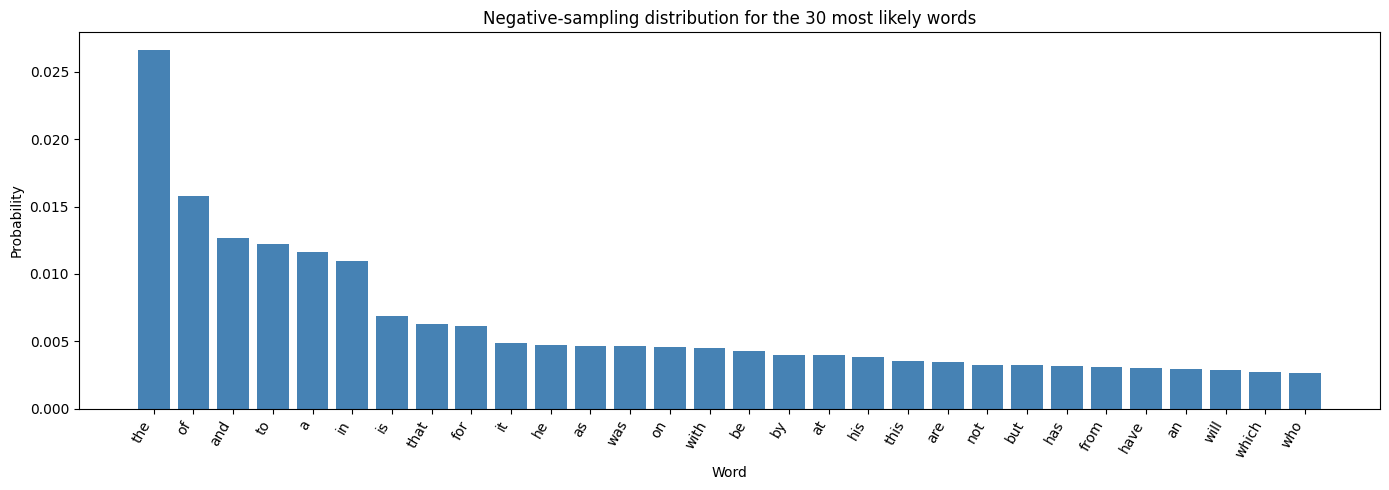

In [11]:
top_n = 30
top_indices = np.argsort(negative_sampling_distribution)[-top_n:][::-1]
top_words = [vocabulary[index] for index in top_indices]
top_probabilities = negative_sampling_distribution[top_indices]

plt.figure(figsize=(14, 5))
plt.bar(top_words, top_probabilities, color="steelblue")
plt.title("Negative-sampling distribution for the 30 most likely words")
plt.xlabel("Word")
plt.ylabel("Probability")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


<div dir="rtl" align="right">

### ماتریس‌های تعبیه‌ی Target و Context

دو ماتریس تعبیه‌ی ۵۰بعدی می‌سازیم: یکی برای واژه‌های Target و دیگری برای واژه‌های Context. هر سطر از هر ماتریس، بردار ۵۰بعدیِ یک واژه از واژگان را نگه می‌دارد.

</div>


In [12]:
print("Target embedding matrix:", target_embeddings.shape)
print("Context embedding matrix:", context_embeddings.shape)

Target embedding matrix: (4397, 50)
Context embedding matrix: (4397, 50)


In [13]:
target_embeddings

array([[ 3.04717080e-03, -1.03998411e-02,  7.50451196e-03, ...,
         2.23595549e-03,  6.78913563e-03,  6.75790695e-04],
       [ 2.89119399e-03,  6.31288226e-03, -1.45715582e-02, ...,
        -9.97246828e-03,  3.99774227e-03, -9.05479055e-03],
       [-3.78162554e-03,  1.29922830e-02, -3.56263971e-03, ...,
        -1.40790886e-03,  1.06598023e-02,  1.57048567e-03],
       ...,
       [ 1.55252096e-02,  1.27913866e-02, -7.50879054e-03, ...,
         1.06096309e-02,  1.31222962e-02,  1.21387353e-03],
       [-5.07580970e-05,  2.34857804e-03, -4.82639384e-03, ...,
         4.74374485e-03, -2.60195790e-03,  1.58812715e-02],
       [ 3.42615475e-03,  2.31542060e-03,  2.11974473e-03, ...,
        -3.60982712e-04,  8.51365463e-04,  1.56718808e-02]],
      shape=(4397, 50))

<div dir="rtl" align="right">

### تابع هزینه، گرادیان و به‌روزرسانی SGNS

برای هر مینی‌بچ با اندازه‌ی $B$، یک زوج مثبتِ Target--Context و $k$ نمونه‌ی منفی برای هر Target داریم. تابع هزینه‌ی Skip-gram with Negative Sampling به‌شکل زیر است:

$$
\mathcal{L} = -\frac{1}{B} \sum_{i=1}^{B} \left[\log \sigma(\mathbf{v}_{t_i}^{\top}\mathbf{v}_{c_i}) + \sum_{j=1}^{k} \log \sigma(-\mathbf{v}_{t_i}^{\top}\mathbf{v}_{n_{ij}})\right]
$$

- $\mathbf{v}_{t_i}$ و $\mathbf{v}_{c_i}$: بردارهای Target و Context برای زوج مثبتِ $i$ام هستند.
- $\mathbf{v}_{n_{ij}}$: بردار $j$امِ نمونه‌های منفیِ Targetِ $i$ام است؛ $k$ تعداد نمونه‌های منفی است.
- $\sigma$: تابع سیگموید و $B$: اندازه‌ی مینی‌بچ است.
- تابع اول مقدار Loss را از Tensorهای PyTorch محاسبه می‌کند، تابع دوم گرادیان‌ها را به‌دست می‌آورد و تابع سوم ماتریس‌های تعبیه را با گرادیان‌ها به‌روزرسانی می‌کند.

</div>


<div dir="rtl" align="right">

### محاسبه تحلیلی گرادیان‌ها (Analytical Gradient)

در این پیاده‌سازی، گرادیان‌های تابع هزینه SGNS به‌صورت تحلیلی (Analytical) و با استفاده از روابط ریاضی محاسبه شده‌اند. به عبارت دیگر، ابتدا مشتق تابع هزینه نسبت به بردارهای Embedding به‌صورت ریاضی به دست آمده و سپس مستقیماً با استفاده از عملیات Tensor در PyTorch 

**تابع هزینه SGNS برای یک نمونه:**

$$
L=-\log\sigma(v_t^T u_c)
-\sum_{i=1}^{K}\log\sigma(-v_t^T u_{n_i})
$$

**گرادیان نسبت به Target Embedding:**

$$
\frac{\partial L}{\partial v_t}
=
(\sigma(v_t^T u_c)-1)u_c
+
\sum_{i=1}^{K}\sigma(v_t^T u_{n_i})u_{n_i}
$$

**گرادیان نسبت به Positive Context Embedding:**

$$
\frac{\partial L}{\partial u_c}
=
(\sigma(v_t^T u_c)-1)v_t
$$

**گرادیان نسبت به Negative Context Embedding:**

$$
\frac{\partial L}{\partial u_{n_i}}
=
\sigma(v_t^T u_{n_i})v_t
$$

در روابط بالا:

- $v_t$: بردار واژه Target
- $u_c$: بردار واژه Positive Context
- $u_{n_i}$: بردار نمونه منفی شماره $i$
- $K$: تعداد Negative Samples
- $\sigma$: تابع Sigmoid


</div>

In [14]:
# Inspect the starting loss and gradient tensor shapes on a small batch.
sample_targets = torch.from_numpy(target_embeddings[:2])
sample_contexts = torch.from_numpy(context_embeddings[2:4])
sample_negatives = torch.from_numpy(context_embeddings[4:8]).reshape(2, 2, embedding_dim)
print(f"Example SGNS loss: {sgns_loss(sample_targets, sample_contexts, sample_negatives):.6f}")
for name, gradient in zip(
    ("Target", "Positive context", "Negative context"),
    sgns_gradients(sample_targets, sample_contexts, sample_negatives),
):
    print(f"{name} gradient shape: {tuple(gradient.shape)}")

Example SGNS loss: 2.079129
Target gradient shape: (2, 50)
Positive context gradient shape: (2, 50)
Negative context gradient shape: (2, 2, 50)


<div dir="rtl" align="right">در بررسی گرادیان، مشتق تحلیلی هر مؤلفه با تقریب تفاضل مرکزی مقایسه می‌شود.</div>

In [15]:
check_sgns_gradients()

Target: max absolute error = 2.74e-11
Positive context: max absolute error = 1.10e-11
Negative context: max absolute error = 3.17e-11
SGNS gradient check passed.


<div dir="rtl" align="right">در پایان هر دوره، هزینه روی همان زوج‌های مثبت و نمونه‌های منفی با بردارهای به‌روزشده محاسبه می‌شود.</div>

In [16]:
target_embedding_matrix, context_embedding_matrix, epoch_losses, fixed_subset_losses = train_sgns(
    target_embeddings, context_embeddings, positive_pairs, word_to_index,
    negative_sampling_distribution, device=device, learning_rate=learning_rate,
    k_negatives=k_negatives, epochs=epochs, batch_size=batch_size,
)
print(f"Final fixed-subset loss: {fixed_subset_losses[-1]:.4f}")

Final fixed-subset loss: 4.1585


Training SGNS: 100%|##########| 50/50 [01:07<00:00,  1.36s/it, fixed_subset_loss=4.1585, loss=4.1586]


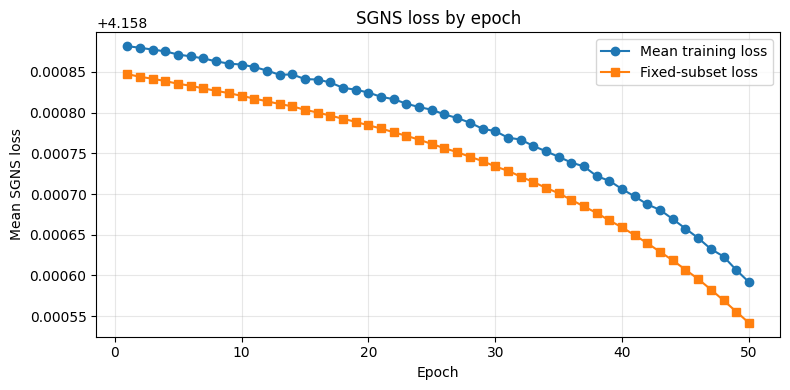

In [17]:
plot_sgns_losses(epoch_losses, fixed_subset_losses)

In [18]:
sgns_embeddings = combine_sgns_embeddings(target_embedding_matrix, context_embedding_matrix)
sgns_embeddings

tensor([[ 0.0074,  0.0015,  0.0096,  ..., -0.0001,  0.0118,  0.0056],
        [ 0.0178, -0.0012, -0.0191,  ..., -0.0017, -0.0094, -0.0153],
        [-0.0025, -0.0028, -0.0116,  ..., -0.0066,  0.0276, -0.0144],
        ...,
        [ 0.0132,  0.0079, -0.0142,  ...,  0.0010,  0.0185,  0.0363],
        [ 0.0144,  0.0245, -0.0169,  ...,  0.0042, -0.0161,  0.0011],
        [-0.0039,  0.0019, -0.0031,  ..., -0.0015,  0.0017,  0.0333]])

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۱.۱</b>

<p><strong>سؤال ۱.</strong> با افزایش تعداد Negative Samples یعنی k، چه تغییری در Gradient مربوط به Target Word Vector یعنی w ایجاد می‌شود؟</p>

<p><strong>سؤال ۲.</strong> چرا پس از Training، دو Matrix به نام W و C را با هم جمع می‌کنند؟</p>

<p><strong>سؤال ۳.</strong> منظور از Fixed-Subset Loss در Training مدل SGNS چیست و چرا از آن استفاده می‌کنیم؟</p>

{{پاسخ_خود_را_اینجا_بنویسید}}

</div>

<div dir="rtl" align="right">

### ۱.۲ ارزیابی Analogy و مقایسه با GloVe

**صورت مسئله**

کیفیت Word Embeddings آموزش‌دیده با SGNS را با استفاده از Nearest Neighbors و Analogy Tests بررسی کنید و نتایج را با Embeddings از پیش آموزش‌دیده‌ی GloVe مقایسه کنید.

**آنچه باید انجام دهید**

- Embeddings از پیش آموزش‌دیده‌ی GloVe با Dimension برابر ۵۰ را بارگذاری کنید.
- Nearest Neighbors مربوط به واژه‌های منتخب را با استفاده از Cosine Similarity پیدا کنید.
- Analogy Queries را با Vector Arithmetic ارزیابی کنید.
- نتایج SGNS و GloVe را برای واژه‌ها و Analogyهای یکسان مقایسه کنید.

**خروجی مورد انتظار**

- فهرست Nearest Neighbors و Cosine Similarity آن‌ها برای هر دو مدل.
- نتایج Analogy Tests و گزارش واژه‌های خارج از Vocabulary یا OOV.
- تحلیل تفاوت نتایج دو مدل و محدودیت‌های این ارزیابی.

**نکات و محدودیت‌ها**

- برای مقایسه‌ی منصفانه، از Analogy Queries یکسان در هر دو مدل استفاده کنید.
- واژه‌های ورودی را از فهرست پاسخ‌های Nearest Neighbors و Analogy حذف کنید.
- مشخص کنید که آیا واژه‌های ورودی در Vocabulary هر مدل موجود هستند یا خیر.

</div>

In [19]:
# GloVe and SGNS nearest-neighbor comparison
from pathlib import Path
from shutil import copyfileobj
from zipfile import ZipFile

# Download the public Kaggle archive only when its extracted GloVe file is absent.
glove_path = Path('datasets/glove.6B.50d.txt')
kaggle_archive = Path('datasets/glove6b50dtxt.zip')
kaggle_url = 'https://www.kaggle.com/api/v1/datasets/download/watts2/glove6b50dtxt'
if not glove_path.exists():
    glove_path.parent.mkdir(parents=True, exist_ok=True)
    if not kaggle_archive.exists():
        print('Downloading GloVe 6B (50d) from Kaggle...')
        urllib.request.urlretrieve(kaggle_url, kaggle_archive)
    with ZipFile(kaggle_archive) as archive:
        glove_member = next((name for name in archive.namelist() if name.endswith('glove.6B.50d.txt')), None)
        if glove_member is None:
            raise FileNotFoundError('The Kaggle archive does not contain glove.6B.50d.txt.')
        with archive.open(glove_member) as source, open(glove_path, 'wb') as destination:
            copyfileobj(source, destination)

# Load every 50-dimensional GloVe word vector from the downloaded dataset.
glove_embeddings = {}
with open(glove_path, encoding='utf-8') as file:
    for line in file:
        word, *values = line.split()
        vector = np.asarray(values, dtype=np.float32)
        if vector.shape == (50,):
            glove_embeddings[word] = vector


In [20]:
glove_embeddings

{'the': array([ 4.1800e-01,  2.4968e-01, -4.1242e-01,  1.2170e-01,  3.4527e-01,
        -4.4457e-02, -4.9688e-01, -1.7862e-01, -6.6023e-04, -6.5660e-01,
         2.7843e-01, -1.4767e-01, -5.5677e-01,  1.4658e-01, -9.5095e-03,
         1.1658e-02,  1.0204e-01, -1.2792e-01, -8.4430e-01, -1.2181e-01,
        -1.6801e-02, -3.3279e-01, -1.5520e-01, -2.3131e-01, -1.9181e-01,
        -1.8823e+00, -7.6746e-01,  9.9051e-02, -4.2125e-01, -1.9526e-01,
         4.0071e+00, -1.8594e-01, -5.2287e-01, -3.1681e-01,  5.9213e-04,
         7.4449e-03,  1.7778e-01, -1.5897e-01,  1.2041e-02, -5.4223e-02,
        -2.9871e-01, -1.5749e-01, -3.4758e-01, -4.5637e-02, -4.4251e-01,
         1.8785e-01,  2.7849e-03, -1.8411e-01, -1.1514e-01, -7.8581e-01],
       dtype=float32),
 ',': array([ 0.013441,  0.23682 , -0.16899 ,  0.40951 ,  0.63812 ,  0.47709 ,
        -0.42852 , -0.55641 , -0.364   , -0.23938 ,  0.13001 , -0.063734,
        -0.39575 , -0.48162 ,  0.23291 ,  0.090201, -0.13324 ,  0.078639,
        -0.4

,Model,Query,Rank,Neighbor,Cosine similarity
0,GloVe 6B (50d),computer,1.0,computers,0.9165
1,GloVe 6B (50d),computer,2.0,software,0.8815
2,GloVe 6B (50d),computer,3.0,technology,0.8526
3,GloVe 6B (50d),computer,4.0,electronic,0.8126
4,GloVe 6B (50d),computer,5.0,internet,0.8060
5,GloVe 6B (50d),book,1.0,books,0.9048
6,GloVe 6B (50d),book,2.0,story,0.8663
7,GloVe 6B (50d),book,3.0,novel,0.8551
8,GloVe 6B (50d),book,4.0,writing,0.8440
9,GloVe 6B (50d),book,5.0,published,0.8439


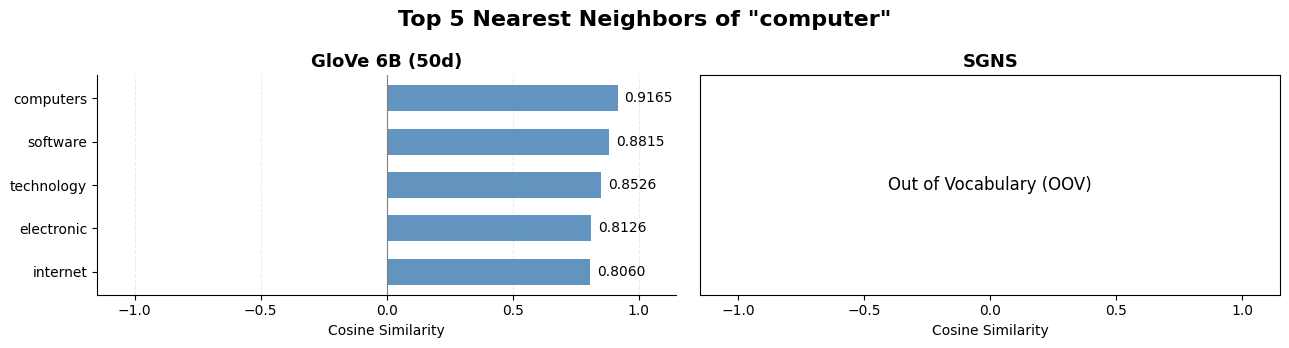

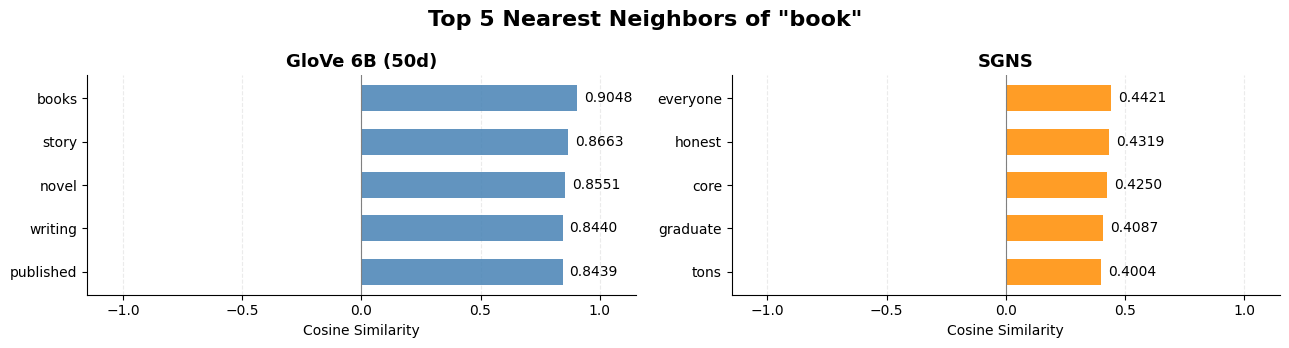

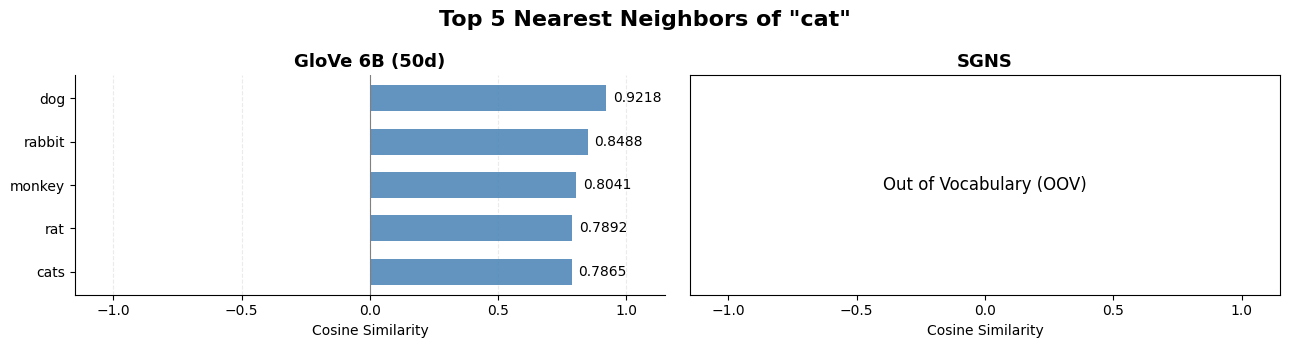

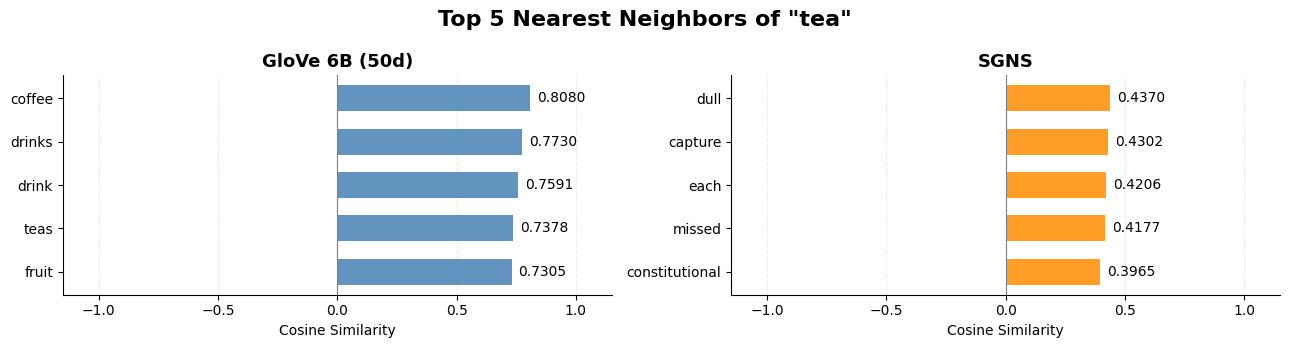

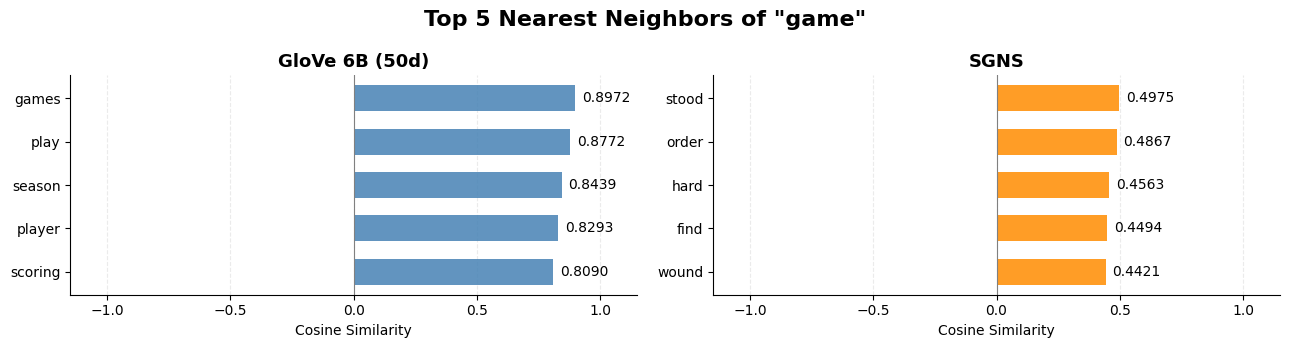

In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration
query_words = ('computer', 'book', 'cat', 'tea', 'game')
top_k = 5

# Embedding models
embedding_models = {
    'GloVe 6B (50d)': (
        list(glove_embeddings),
        np.vstack(list(glove_embeddings.values()))
    ),
    'SGNS': (
        list(vocabulary),
        sgns_embeddings.detach().cpu().numpy().astype(np.float32)
    ),
}

# Find top-k nearest neighbors using cosine similarity
def top_cosine_neighbors(query, words, matrix, k=5):
    word_to_row = {word: row for row, word in enumerate(words)}
    query = query.strip().lower()

    if query not in word_to_row:
        return []

    norms = np.linalg.norm(matrix, axis=1)
    query_row = word_to_row[query]

    if not np.isfinite(norms[query_row]) or norms[query_row] == 0:
        return []

    # Calculate cosine similarity
    with np.errstate(divide='ignore', invalid='ignore'):
        scores = (matrix @ matrix[query_row]) / (
            norms * norms[query_row]
        )

    # Exclude invalid vectors and the query itself
    valid = np.isfinite(scores) & (norms > 0)
    valid[query_row] = False

    candidates = [
        (words[row], float(scores[row]))
        for row in np.flatnonzero(valid)
    ]

    candidates.sort(key=lambda item: (-item[1], item[0]))

    return candidates[:k]


# Calculate nearest neighbors
similarity_rows = []

for model_name, (model_words, model_matrix) in embedding_models.items():
    for query in query_words:

        neighbors = top_cosine_neighbors(
            query, model_words, model_matrix, top_k
        )

        if not neighbors:
            similarity_rows.append({
                'Model': model_name,
                'Query': query,
                'Rank': np.nan,
                'Neighbor': 'OOV / invalid vector',
                'Cosine similarity': np.nan
            })
        else:
            for rank, (neighbor, score) in enumerate(neighbors, start=1):
                similarity_rows.append({
                    'Model': model_name,
                    'Query': query,
                    'Rank': rank,
                    'Neighbor': neighbor,
                    'Cosine similarity': score
                })

# Create results dataframe
top_similar_words = pd.DataFrame(similarity_rows)

display(top_similar_words.round({'Cosine similarity': 4}))


# ============================
# Visualization
# ============================

colors = {
    'GloVe 6B (50d)': 'steelblue',
    'SGNS': 'darkorange'
}

for query in query_words:

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))

    for ax, model_name in zip(axes, embedding_models.keys()):

        data = top_similar_words[
            (top_similar_words['Query'] == query) &
            (top_similar_words['Model'] == model_name)
        ].dropna(subset=['Cosine similarity'])

        data = data.sort_values('Rank')

        ax.set_title(model_name, fontsize=13, fontweight='bold')
        ax.set_xlabel('Cosine Similarity')
        ax.set_xlim(-1.15, 1.15)

        if data.empty:
            ax.text(
                0.5, 0.5, 'Out of Vocabulary (OOV)',
                transform=ax.transAxes,
                ha='center', va='center',
                fontsize=12
            )
            ax.set_yticks([])
            continue

        bars = ax.barh(
            data['Neighbor'],
            data['Cosine similarity'],
            color=colors[model_name],
            alpha=0.85,
            height=0.6
        )

        # Display similarity scores
        ax.bar_label(bars, fmt='%.4f', padding=5)

        # Put the most similar word at the top
        ax.invert_yaxis()

        ax.axvline(0, color='gray', linewidth=0.8)
        ax.grid(axis='x', linestyle='--', alpha=0.25)
        ax.set_axisbelow(True)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    fig.suptitle(
        f'Top {top_k} Nearest Neighbors of "{query}"',
        fontsize=16,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()


Analogy Summary:
Top 5 Analogy Candidates:


,Model,Analogy,Expected,Predicted,Expected in vocabulary,Top-1 correct,Top-5 correct,Status
0,GloVe 6B (50d),man : he :: woman : ?,she,she,True,True,True,OK
1,SGNS,man : he :: woman : ?,she,chicken,True,False,False,OK
2,GloVe 6B (50d),boy : man :: girl : ?,woman,woman,True,True,True,OK
3,SGNS,boy : man :: girl : ?,woman,political,True,False,False,OK


,Model,Analogy,Expected,Rank,Neighbor,Cosine similarity
0,GloVe 6B (50d),man : he :: woman : ?,she,1,she,0.9373
1,GloVe 6B (50d),man : he :: woman : ?,she,2,her,0.8687
2,GloVe 6B (50d),man : he :: woman : ?,she,3,his,0.8303
3,GloVe 6B (50d),man : he :: woman : ?,she,4,having,0.8230
4,GloVe 6B (50d),man : he :: woman : ?,she,5,when,0.8080
5,SGNS,man : he :: woman : ?,she,1,chicken,0.5274
6,SGNS,man : he :: woman : ?,she,2,policy,0.4478
7,SGNS,man : he :: woman : ?,she,3,pink,0.4474
8,SGNS,man : he :: woman : ?,she,4,volunteers,0.4426
9,SGNS,man : he :: woman : ?,she,5,entertained,0.4404


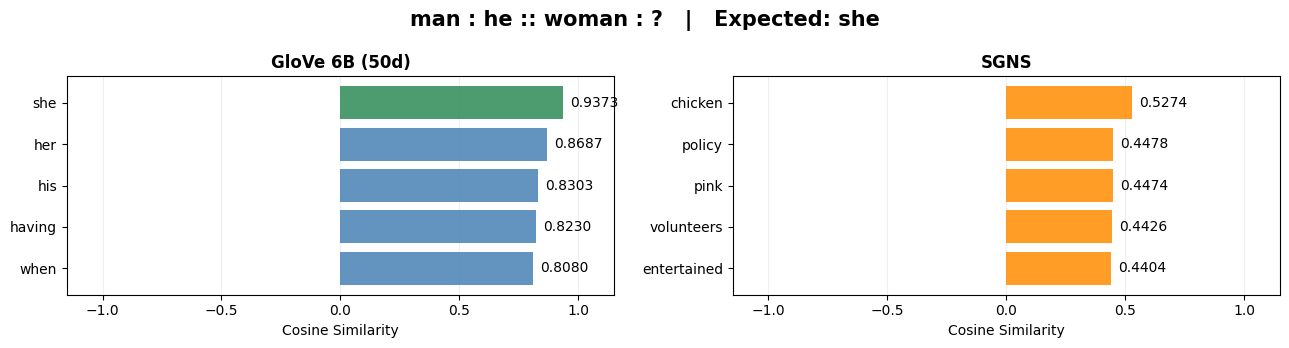

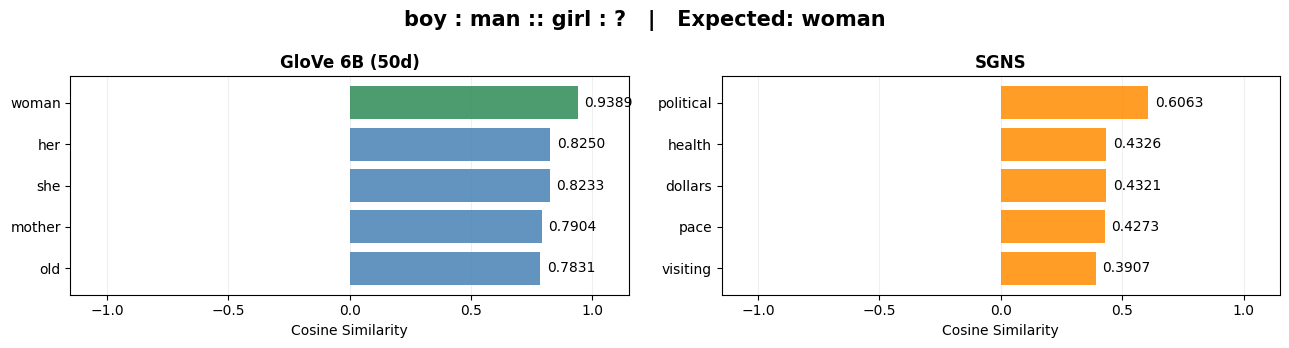

In [22]:

# ==============================================================
# Part 1.2 - Analogy evaluation
# ==============================================================

analogy_queries = [
    ("man", "he", "woman"),
    ("boy", "man", "girl"),
]

expected_answers = ["she", "woman"]
top_k = 5


def analogy(a, b, c, words, matrix, k=5):
    word_to_row = {
        word: i for i, word in enumerate(words)
    }

    # Check out-of-vocabulary words
    missing = [
        w for w in (a, b, c)
        if w not in word_to_row
    ]

    if missing:
        return [], f"OOV: {', '.join(missing)}"

    # Extract input vectors
    va = matrix[word_to_row[a]]
    vb = matrix[word_to_row[b]]
    vc = matrix[word_to_row[c]]

    # Vector arithmetic: a:b :: c:?
    query_vector = vb - va + vc

    # Calculate vector norms
    query_norm = np.linalg.norm(query_vector)
    norms = np.linalg.norm(matrix, axis=1)

    if not np.isfinite(query_norm) or query_norm == 0:
        return [], "Invalid query vector"

    # Calculate cosine similarity
    with np.errstate(divide='ignore', invalid='ignore'):
        scores = (matrix @ query_vector) / (
            norms * query_norm
        )

    scores[~np.isfinite(scores)] = -np.inf

    # Exclude all input words
    for word in (a, b, c):
        scores[word_to_row[word]] = -np.inf

    # Find top-k candidates
    ranked_indices = np.argsort(-scores)

    top_indices = [
        i for i in ranked_indices
        if np.isfinite(scores[i])
    ][:k]

    neighbors = [
        (words[i], float(scores[i]))
        for i in top_indices
    ]

    return neighbors, "OK"


# Evaluate both embedding models
analogy_rows = []
summary_rows = []

for (a, b, c), expected in zip(
    analogy_queries, expected_answers
):
    query = f"{a} : {b} :: {c} : ?"

    for model_name, (words, matrix) in embedding_models.items():

        neighbors, status = analogy(
            a, b, c, words, matrix, top_k
        )

        predicted = neighbors[0][0] if neighbors else None
        expected_in_vocab = expected in set(words)

        summary_rows.append({
            "Model": model_name,
            "Analogy": query,
            "Expected": expected,
            "Predicted": predicted,
            "Expected in vocabulary": expected_in_vocab,
            "Top-1 correct": predicted == expected if neighbors else np.nan,
            "Top-5 correct": expected in [w for w, _ in neighbors] if neighbors else np.nan,
            "Status": status
        })

        for rank, (word, score) in enumerate(neighbors, 1):
            analogy_rows.append({
                "Model": model_name,
                "Analogy": query,
                "Expected": expected,
                "Rank": rank,
                "Neighbor": word,
                "Cosine similarity": score
            })


analogy_results = pd.DataFrame(analogy_rows)
analogy_summary = pd.DataFrame(summary_rows)

print("Analogy Summary:")
display(analogy_summary)

print("Top 5 Analogy Candidates:")
display(analogy_results.round(4))


# ==============================================================
# Visualization
# ==============================================================

for (a, b, c), expected in zip(
    analogy_queries, expected_answers
):
    query = f"{a} : {b} :: {c} : ?"

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))

    for ax, model_name, color in zip(
        axes,
        embedding_models.keys(),
        ["steelblue", "darkorange"]
    ):
        data = analogy_results[
            (analogy_results["Analogy"] == query) &
            (analogy_results["Model"] == model_name)
        ].sort_values("Rank")

        ax.set_title(model_name, fontweight="bold")
        ax.set_xlim(-1.15, 1.15)
        ax.set_xlabel("Cosine Similarity")

        if data.empty:
            ax.text(
                0.5, 0.5, "OOV / Invalid",
                transform=ax.transAxes,
                ha="center", va="center"
            )
            ax.set_yticks([])
            continue

        # Highlight the expected answer in green
        colors = [
            "seagreen" if word == expected else color
            for word in data["Neighbor"]
        ]

        bars = ax.barh(
            data["Neighbor"],
            data["Cosine similarity"],
            color=colors,
            alpha=0.85
        )

        ax.bar_label(bars, fmt="%.4f", padding=5)
        ax.invert_yaxis()
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)

    fig.suptitle(
        f"{query}   |   Expected: {expected}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


Words not in my Vocabulary

In [23]:
sgns_vocab = set(vocabulary)

oov_words = [
    word for word in glove_embeddings
    if word not in sgns_vocab
    and word.isalpha()
    and len(word) >= 4
]

print("Total OOV words:", len(oov_words))


import random
print(random.sample(oov_words, 10))

Total OOV words: 311815
['infra', 'risking', 'bouchareb', 'unbeliever', 'persuaders', 'résumé', 'oligarch', 'littéraires', 'postbank', 'graps']


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۱.۲</b>

<p><strong>سؤال.</strong> چرا مدل SGNS این تمرین ممکن است در Analogy Tests از GloVe ضعیف‌تر باشد؟ آیا Nearest Neighbors و چند Analogy Test برای سنجش کیفیت کلی Embeddings کافی‌اند؟ روش Parallelogram چه محدودیت‌هایی دارد؟</p>

{{پاسخ_خود_را_اینجا_بنویسید}}

</div>

<div dir="rtl" align="right">

### ۱.۳ نمایش PCA برای Word Embeddings

**صورت مسئله**

برای بررسی بصری Word Embeddings، بردارهای واژه‌های انتخاب‌شده از SGNS و GloVe را با استفاده از Principal Component Analysis (PCA) به دو Dimension کاهش دهید و نتایج را رسم کنید.

**آنچه باید انجام دهید**

- مجموعه‌ای از واژه‌های مشترک را از Vocabulary هر دو مدل انتخاب کنید.
- Embeddings مربوط به واژه‌های منتخب را به دو Dimension کاهش دهید.
- برای هر مدل یک Plot دوبعدی رسم کنید و نام هر واژه را روی Plot نمایش دهید.

**خروجی مورد انتظار**

- یک PCA Plot برای SGNS و یک PCA Plot برای GloVe.
- گزارش مجموع Explained Variance Ratio مربوط به دو Principal Components اول برای هر مدل.
- تحلیل الگوهای قابل مشاهده و محدودیت‌های PCA Visualization.

**نکات و محدودیت‌ها**

- PCA را برای هر مدل به‌صورت جداگانه Fit کنید.

</div>

In [24]:
# Helper for displaying the projection of one embedding model.
def plot_word_projection(ax, projected, words, pca, model_name, color):
    ax.scatter(projected[:, 0], projected[:, 1], color=color, s=80, alpha=0.85)
    for word, (x, y) in zip(words, projected):
        ax.annotate(word, (x, y), xytext=(5, 5), textcoords="offset points")
    pc1, pc2 = pca.explained_variance_ratio_
    ax.set(title=model_name, xlabel=f"PC1 ({pc1:.2%})", ylabel=f"PC2 ({pc2:.2%})")
    ax.axhline(0, color="gray", alpha=0.3)
    ax.axvline(0, color="gray", alpha=0.3)
    ax.grid(alpha=0.2)
    ax.margins(0.15)

<div dir="rtl" align="right">

روش PCA با استفاده از عملیات جبر خطی، بردارهای ویژه ماتریس کوواریانس را به‌دست می‌آورد که بر یکدیگر عمود هستند. این بردارها جهت‌هایی را مشخص می‌کنند که بیشترین واریانس داده‌ها در آن‌ها قرار دارد.

هرچه یک مؤلفه اصلی بتواند بخش بیشتری از تغییرات داده‌ها را توصیف کند، Explained Variance Ratio آن بیشتر خواهد بود. مؤلفه اصلی اول (PC1) بیشترین واریانس را توضیح می‌دهد و مؤلفه دوم (PC2)، در جهت عمود بر مؤلفه اول، بیشترین واریانس باقی‌مانده را پوشش می‌دهد.

</div>

Common words: ['man', 'woman', 'boy', 'girl', 'he', 'she', 'him', 'her', 'father', 'mother', 'king', 'queen']
Excluded words (OOV): []


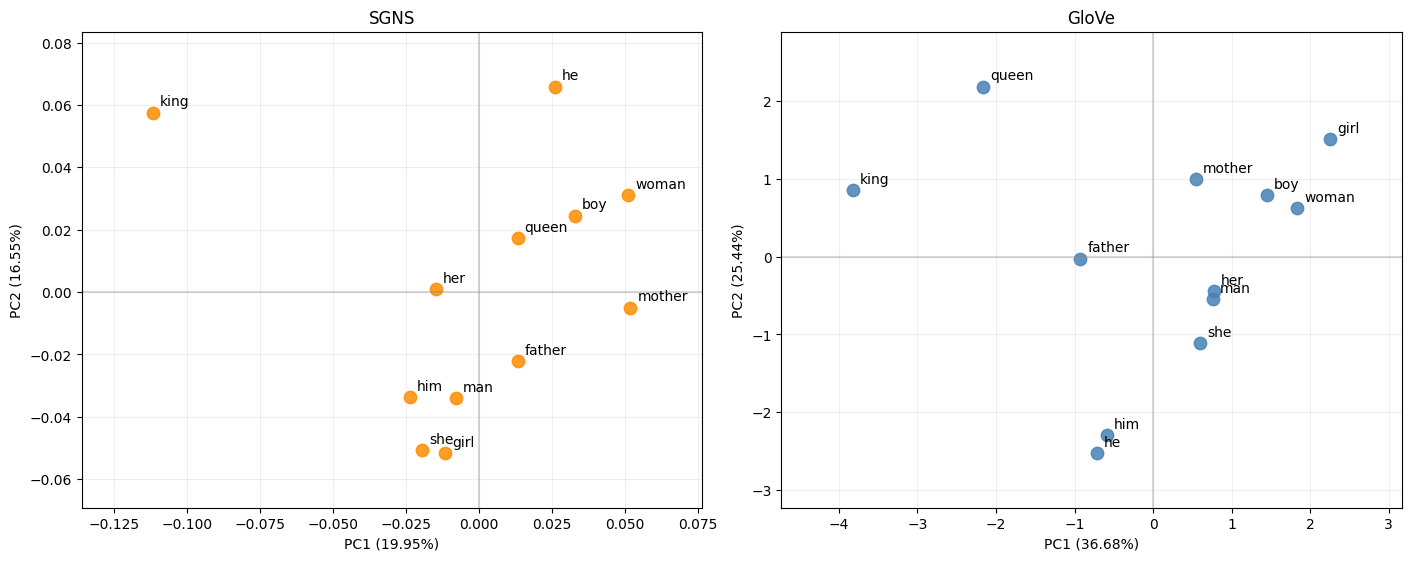

,PC1,PC2,PC1 + PC2
SGNS,19.95%,16.55%,36.51%
GloVe,36.68%,25.44%,62.12%


In [25]:
# ==============================================================
# Part 1.3 - PCA visualization
# ==============================================================

words_to_plot = [
    "man", "woman", "boy", "girl",
    "he", "she", "him", "her",
    "father", "mother", "king", "queen",
]

# TODO: Apply PCA to the selected SGNS embeddings and plot the results.
common_words = [word for word in words_to_plot if word in word_to_index and word in glove_embeddings]
missing_words = [word for word in words_to_plot if word not in common_words]
print("Common words:", common_words)
print("Excluded words (OOV):", missing_words)
if len(common_words) < 2:
    raise ValueError("PCA requires at least two of the selected words in both models.")

sgns_rows = [word_to_index[word] for word in common_words]
sgns_vectors = sgns_embeddings[sgns_rows].detach().cpu().numpy()
pca_sgns = PCA(n_components=2)
sgns_2d = pca_sgns.fit_transform(sgns_vectors)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout="constrained")
plot_word_projection(axes[0], sgns_2d, common_words, pca_sgns, "SGNS", "darkorange")

# TODO: Apply PCA separately to the selected GloVe embeddings and plot them.
glove_vectors = np.stack([glove_embeddings[word] for word in common_words])
pca_glove = PCA(n_components=2)
glove_2d = pca_glove.fit_transform(glove_vectors)
plot_word_projection(axes[1], glove_2d, common_words, pca_glove, "GloVe", "steelblue")
plt.show()

# TODO: Report the explained variance for the first two components.
variance_table = pd.DataFrame(
    [pca_sgns.explained_variance_ratio_, pca_glove.explained_variance_ratio_],
    index=["SGNS", "GloVe"],
    columns=["PC1", "PC2"],
)
variance_table["PC1 + PC2"] = variance_table.sum(axis=1)
display(variance_table.style.format("{:.2%}"))

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۱.۳</b>

<p><strong>سؤال.</strong> Plotهای PCA چه اطلاعاتی درباره‌ی توزیع واژه‌ها و روابط میان آن‌ها نشان می‌دهند؟ مجموع Explained Variance Ratio مربوط به دو Principal Components اول چه مفهومی دارد؟ چرا نباید مختصات واژه‌ها را بین دو Plot مستقیما مقایسه کرد؟</p>

{{پاسخ_خود_را_اینجا_بنویسید}}

</div>

<div dir="rtl" align="right">

### ۲.۱ پیاده‌سازی Logistic Regression از پایه

**صورت مسئله**

یک Logistic Regression برای پیش‌بینی Positive یا Negative بودن Sentiment متن آموزش دهید. برای این کار از Features استخراج‌شده از متن استفاده کنید و Training را با پیاده‌سازی دستی Stochastic Gradient Descent (SGD) انجام دهید.

**آنچه باید انجام دهید**

- Positive و Negative Lexiconها و مجموعه‌داده‌ی IMDB را بارگذاری کنید.
- متن هر Review را به یک Feature Vector عددی تبدیل کنید. برای شروع، می‌توانید از Features پیشنهادی زیر استفاده کنید:
  - تعداد واژه‌های موجود در Positive Lexicon.
  - تعداد واژه‌های موجود در Negative Lexicon.
  - وجود یا عدم وجود واژه‌ی "no".
  - تعداد Pronounهای مشخص‌شده در کد.
  - وجود یا عدم وجود علامت "!".
  - لگاریتم تعداد Tokenهای متن.
- داده‌ها را به Train و Test تقسیم کنید و Featureها را با استفاده از آمار Training Set استانداردسازی کنید.
- Logistic Regression را با Manual SGD آموزش دهید.
- Training Loss، Weights و Bias را گزارش کنید.
- عملکرد مدل را با Classification Threshold برابر 0.5 ارزیابی کنید و نتایج را برای Threshold برابر 0.8 نیز بررسی کنید.

**خروجی مورد انتظار**

- نمودار Training Cross-Entropy برحسب Epoch.
- Weights و Bias آموزش‌دیده‌ی مدل.
- Confusion Matrix و معیارهای Accuracy، Precision، Recall و F1 برای Threshold برابر 0.5.
- مقایسه‌ی Precision و Recall برای Thresholdهای 0.5 و 0.8.

**نکات و محدودیت‌ها**

- آموزش Logistic Regression باید به‌صورت دستی انجام شود. از مدل آماده‌ی Logistic Regression برای Training استفاده نکنید.
- از یک Train/Test Split ثابت و Stratified استفاده کنید.
- برای جلوگیری از Test Data Leakage، Normalization Statistics را فقط از Training Set محاسبه کنید.
- در تحلیل، تاثیر Classification Threshold بر Precision و Recall را توضیح دهید.

</div>

In [26]:
# Part 2.1 - Logistic Regression from scratch
# Cell 1: Download and load the datasets

from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd

dataset_dir = Path("datasets")
dataset_dir.mkdir(exist_ok=True)

base_url = "https://raw.githubusercontent.com/ILoveBacteria/nlp-homework/master/hw2/datasets"

for filename in ("imdb_2k.csv", "positive_words.txt", "negative_words.txt"):
    urlretrieve(f"{base_url}/{filename}", dataset_dir / filename)

df = pd.read_csv(dataset_dir / "imdb_2k.csv")

with (dataset_dir / "positive_words.txt").open(encoding="utf-8") as f:
    positive_lexicon = {line.strip().lower() for line in f if line.strip()}

with (dataset_dir / "negative_words.txt").open(encoding="utf-8") as f:
    negative_lexicon = {line.strip().lower() for line in f if line.strip()}

In [27]:
# Cell 2: IMDb dataset
df

,text,label
0,The Good: I liked this movie because it was th...,0
1,"I enjoy movies like this for their spirit, no ...",1
2,Slaughter High the tale of revenge by a nerdy ...,0
3,I have a six month old baby at home and time t...,1
4,When will the hurting stop? I never want to se...,0
...,...,...
1995,"I am 17, and I still like most of the Scooby D...",0
1996,Not sure if I'm referring to those who labeled...,0
1997,I don't understand why the other comments focu...,1
1998,"Ah WINTER KILLS , based on the novel by Richar...",0


In [28]:
# Cell 3: Sample positive words
sorted(positive_lexicon)[:20]

['a+',
 'abound',
 'abounds',
 'abundance',
 'abundant',
 'accessable',
 'accessible',
 'acclaim',
 'acclaimed',
 'acclamation',
 'accolade',
 'accolades',
 'accommodative',
 'accomodative',
 'accomplish',
 'accomplished',
 'accomplishment',
 'accomplishments',
 'accurate',
 'accurately']

In [29]:
# Cell 4: Sample negative words
sorted(negative_lexicon)[:20]

['2-faced',
 '2-faces',
 'abnormal',
 'abolish',
 'abominable',
 'abominably',
 'abominate',
 'abomination',
 'abort',
 'aborted',
 'aborts',
 'abrade',
 'abrasive',
 'abrupt',
 'abruptly',
 'abscond',
 'absence',
 'absent-minded',
 'absentee',
 'absurd']

In [30]:
# Cell 1: Feature extraction functions

import math

PRONOUNS = {
    "i", "me", "my", "mine", "myself",
    "we", "us", "our", "ours", "ourselves",
    "you", "your", "yours", "yourself", "yourselves",
}


def tokenize(text: str) -> list[str]:
    text = text.lower().replace("’", "'")

    for mark in ".,:;!?()":
        text = text.replace(mark, f" {mark} ")

    return text.split()

def count_positive_words(text: str) -> int:
    return sum(token in positive_lexicon for token in tokenize(text))


def count_negative_words(text: str) -> int:
    return sum(token in negative_lexicon for token in tokenize(text))


def has_no(text: str) -> int:
    return int("no" in tokenize(text))


def count_pronouns(text: str) -> int:
    # Count the pronoun in contractions such as "I'm" and "you've".
    return sum(token.split("'", 1)[0] in PRONOUNS for token in tokenize(text))


def has_exclamation(text: str) -> int:
    return int("!" in text)


def log_token_count(text: str) -> float:
    token_count = len(tokenize(text))
    return math.log(max(1, token_count))

In [31]:
# Cell 2: Build and display the feature DataFrame

texts = df["text"].fillna("")

features_df = pd.DataFrame({
    "positive_count": texts.map(count_positive_words),
    "negative_count": texts.map(count_negative_words),
    "has_no": texts.map(has_no),
    "pronoun_count": texts.map(count_pronouns),
    "has_exclamation": texts.map(has_exclamation),
    "log_token_count": texts.map(log_token_count),
})

y = df["label"]

features_df

,positive_count,negative_count,has_no,pronoun_count,has_exclamation,log_token_count
0,6,13,0,4,0,4.700480
1,13,10,1,9,0,5.327876
2,2,11,0,1,0,4.543295
3,6,3,0,9,0,5.438079
4,2,5,0,2,0,4.418841
...,...,...,...,...,...,...
1995,14,10,0,19,1,5.736572
1996,6,8,1,3,0,5.209486
1997,8,4,0,3,0,5.056246
1998,6,19,1,4,0,5.648974


In [32]:
# Stratified split and standardization
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    features_df, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train = y_train.to_numpy(dtype=int)
y_test = y_test.to_numpy(dtype=int)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (1600, 6)
Test: (400, 6)


Final training loss = 0.5382
Bias = -0.0745
positive_count     1.6124
negative_count    -1.5502
has_no            -0.3366
pronoun_count     -0.1992
has_exclamation    0.0437
log_token_count   -0.1261
Name: Weight, dtype: float64


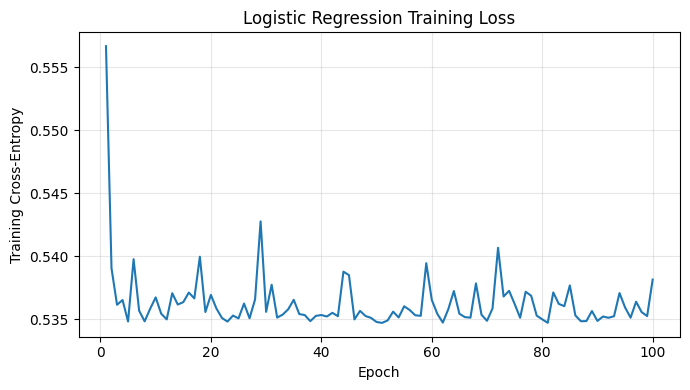

In [33]:
# Linear logistic regression with manual SGD
import numpy as np
import matplotlib.pyplot as plt


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


eta = 0.01
epochs = 100
rng = np.random.default_rng(42)

weights = np.zeros(X_train.shape[1])
bias = 0.0
training_losses = []

for epoch in range(epochs):
    for i in rng.permutation(len(X_train)):
        x_i = X_train[i]
        y_i = y_train[i]

        probability = sigmoid(x_i @ weights + bias)
        error = probability - y_i

        weights -= eta * error * x_i
        bias -= eta * error

    train_logits = X_train @ weights + bias
    # Binary cross-entropy computed directly from logits.
    loss = np.mean(np.logaddexp(0, train_logits) - y_train * train_logits)
    training_losses.append(loss)

print(f"Final training loss = {training_losses[-1]:.4f}")
print(f"Bias = {bias:.4f}")
print(pd.Series(weights, index=features_df.columns, name="Weight").round(4))

plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), training_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Cross-Entropy")
plt.title("Logistic Regression Training Loss")
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

,Predicted positives,Accuracy,Precision,Recall,F1
Threshold,,,,,
0.5,209,0.7075,0.6986,0.730,0.7139
0.8,63,0.6175,0.8730,0.275,0.4183


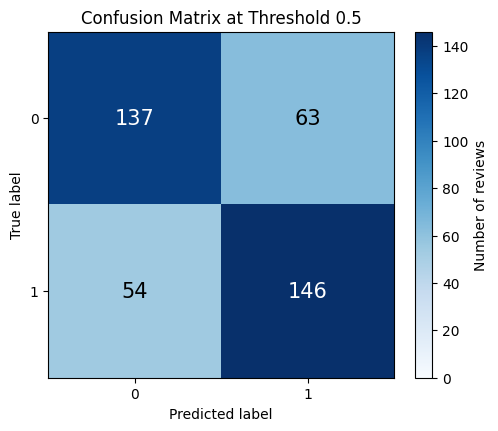

In [34]:
# Test metrics and confusion matrix
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

test_probabilities = sigmoid(X_test @ weights + bias)
metrics = []

for threshold in (0.5, 0.8):
    predictions = (test_probabilities >= threshold).astype(int)
    metrics.append({
        "Threshold": threshold,
        "Predicted positives": predictions.sum(),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
    })

test_metrics = pd.DataFrame(metrics).set_index("Threshold")
display(test_metrics.round(4))

predictions_05 = (test_probabilities >= 0.5).astype(int)
matrix = confusion_matrix(y_test, predictions_05, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5.2, 4.2), layout="constrained")
heatmap = ax.imshow(matrix, cmap="Blues", vmin=0)
for (row, column), count in np.ndenumerate(matrix):
    color = "white" if count > matrix.max() / 2 else "black"
    ax.text(column, row, str(count), ha="center", va="center",
            fontsize=15, color=color)

ax.set_xticks([0, 1], labels=["0", "1"])
ax.set_yticks([0, 1], labels=["0", "1"])
ax.set(xlabel="Predicted label", ylabel="True label",
       title="Confusion Matrix at Threshold 0.5")
fig.colorbar(heatmap, ax=ax, label="Number of reviews")
plt.show()

<div dir="rtl" align="right">

**تأثیر آستانهٔ تصمیم‌گیری**

با افزایش آستانه از ۰٫۵ به ۰٫۸، تعداد پیش‌بینی‌های کلاس مثبت از 209 به 63 رسید.
Precision از 0.6986 به 0.8730 و Recall از 0.7300 به 0.2750 رسید.
آستانهٔ بالاتر فقط نمونه‌هایی را مثبت حساب می‌کند که احتمال پیش‌بینی‌شدهٔ بالاتری دارند.
بنابراین تعداد مثبت‌های واقعیِ شناسایی‌شده و Recall نمی‌تواند افزایش پیدا کند.
تغییر Precision به نسبت مثبت‌های واقعی و کاذب در میان پیش‌بینی‌های باقی‌مانده بستگی دارد.

</div>

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۲.۱</b>

<p><strong>سؤال ۱.</strong> Weights مربوط به Positive-word Feature و Negative-word Feature را تفسیر کنید. علامت هر Weight چه ارتباطی با پیش‌بینی Positive Sentiment دارد؟ آیا این رابطه لزوما نشان‌دهنده‌ی رابطه‌ی علت و معلولی است؟</p>

<p><strong>سؤال ۲.</strong> اگر Classification Threshold از 0.5 به 0.8 افزایش یابد، چه تغییری در Precision و Recall مشاهده می‌کنید؟ پاسخ خود را بر اساس خروجی واقعی مدل توضیح دهید.</p>

{{پاسخ_خود_را_اینجا_بنویسید}}

</div>

<div dir="rtl" align="right">

### ۲.۲ مقایسه Learning Rate و بررسی Decision Boundary

**صورت مسئله**

بررسی کنید که تغییر Learning Rate چه تأثیری بر روند Training مدل Logistic Regression دارد. دو مقدار Learning Rate برابر با 0.01 و 15.0 را مقایسه کرده و Decision Boundary مدل را در فضای دو Feature با بزرگ‌ترین قدر مطلق وزن در مدل بخش ۲.۱ نمایش دهید.

**آنچه باید انجام دهید**

- مدل Logistic Regression را با هر دو Learning Rate آموزش دهید.
- برای مقایسه‌ی منصفانه، Initial Weights، Bias و ترتیب Training Examples را بین دو آزمایش یکسان نگه دارید.
- Training Cross-Entropy را پس از هر Epoch محاسبه و Loss History دو مدل را در یک Plot رسم کنید.
- Decision Boundary مدل آموزش‌دیده در بخش ۲.۱ را با استفاده از دو Feature با بزرگ‌ترین قدر مطلق وزن رسم کنید.

**خروجی مورد انتظار**

- نمودار مقایسه‌ی Training Loss برای دو Learning Rate.
- نمودار Decision Boundary همراه با نمونه‌های هر دو Class.
- تحلیل رفتار Loss و تأثیر Learning Rate بر پایداری Training.

**نکات و محدودیت‌ها**

- اگر مقادیر غیرمتناهی مانند NaN یا Infinity ایجاد شدند، آن‌ها را شناسایی و گزارش کنید.
- هنگام رسم Decision Boundary، چهار Feature دیگر را روی مقدار استانداردشده‌ی صفر ثابت نگه دارید.

</div>

Learning rate 0.01: first loss = 0.5567, last loss = 0.5364
Learning rate 15: first loss = 27.0656, last loss = 18.9000


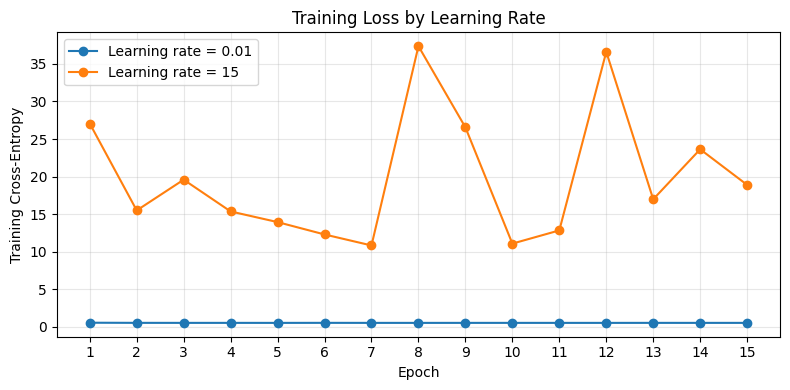

In [35]:
# Compare learning rates with the same starting point and sample order.
eta_normal = 0.01
eta_large = 15.0
comparison_epochs = 15

comparison_rng = np.random.default_rng(42)
epoch_orders = [
    comparison_rng.permutation(len(X_train))
    for _ in range(comparison_epochs)
]


def train_logistic_sgd(X, y, learning_rate, sample_orders):
    model_weights = np.zeros(X.shape[1])
    model_bias = 0.0
    loss_history = []

    for epoch_number, sample_order in enumerate(sample_orders, start=1):
        for i in sample_order:
            x_i = X[i]
            probability = sigmoid(x_i @ model_weights + model_bias)
            error = probability - y[i]

            model_weights -= learning_rate * error * x_i
            model_bias -= learning_rate * error

        logits = X @ model_weights + model_bias
        loss = np.mean(np.logaddexp(0, logits) - y * logits)

        if not np.isfinite(loss):
            print(f"Non-finite loss at epoch {epoch_number} (learning rate {learning_rate:g}): {loss}")
            break

        loss_history.append(loss)

    return loss_history


loss_by_rate = {}
for rate in (eta_normal, eta_large):
    loss_by_rate[rate] = train_logistic_sgd(X_train, y_train, rate, epoch_orders)

fig, ax = plt.subplots(figsize=(8, 4))
for rate, losses in loss_by_rate.items():
    ax.plot(range(1, len(losses) + 1), losses, marker="o",
            label=f"Learning rate = {rate:g}")
    if losses:
        print(f"Learning rate {rate:g}: first loss = {losses[0]:.4f}, "
              f"last loss = {losses[-1]:.4f}")

ax.set(
    xlabel="Epoch",
    ylabel="Training Cross-Entropy",
    title="Training Loss by Learning Rate",
    xticks=range(1, comparison_epochs + 1),
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

,Weight
positive_count,1.6124
negative_count,-1.5502


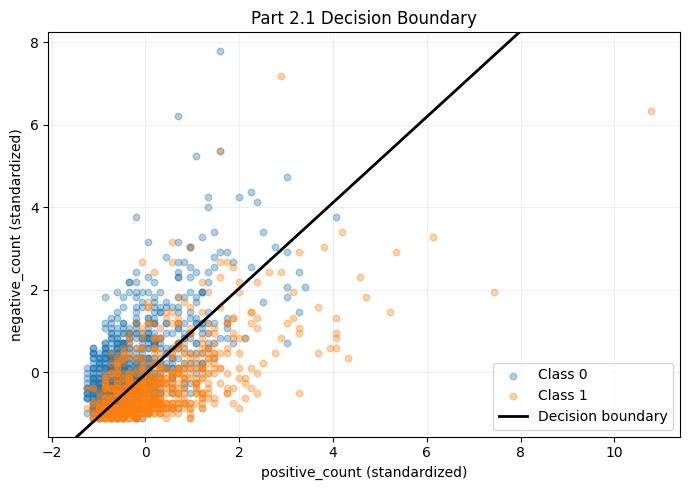

In [36]:
# Plot the decision boundary of the trained model from Part 2.1.
strongest_features = np.argsort(-np.abs(weights), kind="stable")[:2]
first, second = strongest_features
first_name, second_name = features_df.columns[strongest_features]
selected_weights = pd.Series(
    weights[strongest_features], index=[first_name, second_name], name="Weight"
)
display(selected_weights.to_frame().round(4))

fig, ax = plt.subplots(figsize=(7, 5))
for label, color in [(0, "tab:blue"), (1, "tab:orange")]:
    examples = X_train[y_train == label]
    ax.scatter(examples[:, first], examples[:, second], s=22,
               alpha=0.35, color=color, label=f"Class {label}")

# At p = 0.5, the logit is zero. All other standardized features are zero.
y_line = np.array(ax.get_ylim())
x_line = -(weights[second] * y_line + bias) / weights[first]
ax.plot(x_line, y_line, color="black", linewidth=2, label="Decision boundary")

ax.set(
    xlabel=f"{first_name} (standardized)",
    ylabel=f"{second_name} (standardized)",
    title="Part 2.1 Decision Boundary",
    ylim=y_line,
)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

<div dir="rtl" align="right">

**اثر نرخ یادگیری بر پایداری آموزش**

در این اجرا، با نرخ یادگیری ۰٫۰۱، Cross-Entropy از 0.5567 در دورهٔ اول به 0.5364 در دورهٔ پانزدهم رسید. با نرخ ۱۵٫۰، Loss بین 9.7881 و 32.0731 نوسان کرد. گام‌های بزرگ SGD می‌توانند از ناحیهٔ کم‌هزینه عبور کنند و باعث نوسان Loss شوند. در هر دو اجرا، Loss در تمام ۱۵ دوره متناهی بود.

**نمایش مرز تصمیم**

دو محور با بزرگ‌ترین قدر مطلق وزن در مدل بخش ۲.۱ انتخاب شده‌اند. خط، محل احتمال ۰٫۵ در برشی از مدل است که چهار ویژگی دیگر روی صفر استانداردشده، معادل میانگین آموزشی هر ویژگی، ثابت هستند. نقاط، نمونه‌های آموزشی هر دو کلاس را در فضای این دو ویژگی نشان می‌دهند.

</div>

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۲.۲</b>

<p><strong>سؤال.</strong> پدیده‌ی Overshooting چیست؟ چرا Training Loss برای دو مقدار Learning Rate متفاوت رفتار متفاوتی دارد؟ نمودار Decision Boundary چه اطلاعاتی درباره‌ی جداسازی دو Class در فضای دو Feature اول ارائه می‌دهد؟</p>

{{پاسخ_خود_را_اینجا_بنویسید}}

</div>

---

<div dir="rtl" align="right">

## ۳. ارزیابی شباهت معنایی واژه‌ها و جمله‌ها

در این سؤال با استفاده از بردارهای از پیش آموزش‌دیده‌ی GloVe، شباهت معنایی واژه‌ها و جمله‌ها را محاسبه و با قضاوت انسانی مقایسه می‌کنید. ابتدا توابع محاسبه شباهت را پیاده‌سازی کرده، سپس عملکرد آن‌ها را روی مجموعه‌داده‌های واقعی ارزیابی می‌کنید. در پایان نیز محدودیت‌های این روش‌ها را بررسی خواهید کرد. نیازی به آموزش مدل جدید نیست.

</div>


<div dir="rtl" align="right">

### مجموعه‌داده‌ها و مدل مورد استفاده

در تمام بخش‌های سؤال دوم از بردارهای **GloVe 6B با بُعد ۵۰** استفاده کنید. واژگان این سؤال به ۵۰٬۰۰۰ واژه نخست فایل GloVe محدود است. سلول‌های زیر ۵۰٬۰۰۰ واژه نخست GloVe و مجموعه‌داده‌های موردنیاز را بارگذاری می‌کنند.

- **WordSim-353:** شامل ۳۵۳ جفت‌واژه با امتیاز انسانی از صفر تا ۱۰، با تأکید بر ارتباط معنایی (Relatedness).
- **SimLex-999:** شامل ۹۹۹ جفت‌واژه با امتیاز انسانی از صفر تا ۱۰، با تأکید بر شباهت معنایی (Similarity).
- **STS Benchmark:** شامل جفت‌جمله‌های دارای امتیاز شباهت انسانی. در این تمرین از ۱۳۷۹ جفت‌جمله بخش Test استفاده می‌شود که امتیاز آن‌ها در نسخه مورد استفاده بین صفر و یک است. ستون‌های `sentence1` و `sentence2` متن جملات و ستون `score` امتیاز انسانی را نشان می‌دهند.

از همین داده‌ها و ترتیب سطرهای آن‌ها در ارزیابی استفاده کنید؛ رکوردهای تکراری را حذف نکنید.

</div>


In [37]:
# ==============================================================
# Question 3 - Model and datasets
# ==============================================================

# Load the first 50,000 pretrained GloVe vectors.
from itertools import islice
from pathlib import Path
from shutil import copyfileobj
from urllib.request import urlretrieve
from zipfile import ZipFile

import numpy as np

glove_path = Path("datasets/glove.6B.50d.txt")
archive_path = glove_path.parent / "glove6b50dtxt.zip"
glove_url = "https://www.kaggle.com/api/v1/datasets/download/watts2/glove6b50dtxt"

if not glove_path.exists():
    glove_path.parent.mkdir(parents=True, exist_ok=True)

    if not archive_path.exists():
        print("Downloading GloVe 6B (50d)...")
        urlretrieve(glove_url, archive_path)

    with ZipFile(archive_path) as archive:
        member = next(
            (name for name in archive.namelist() if Path(name).name == glove_path.name),
            None,
        )
        if member is None:
            raise FileNotFoundError(f"{glove_path.name} was not found in the ZIP archive.")

        with archive.open(member) as source, glove_path.open("wb") as destination:
            copyfileobj(source, destination)

similarity_embeddings = {}
glove_ranks = {}

with glove_path.open(encoding="utf-8") as f:
    for rank, line in enumerate(islice(f, 50_000), start=1):
        word, *values = line.split()
        similarity_embeddings[word] = np.asarray(values, dtype=np.float32)
        glove_ranks[word] = rank

assert len(similarity_embeddings) == 50_000
assert all(vector.shape == (50,) for vector in similarity_embeddings.values())

print("Vocabulary size:", len(similarity_embeddings))
print("Embedding dimension:", len(next(iter(similarity_embeddings.values()))))

Vocabulary size: 50000
Embedding dimension: 50


In [38]:
import pandas as pd

base_url = "https://raw.githubusercontent.com/ILoveBacteria/nlp-homework/master/hw2/datasets"

wordsim = pd.read_csv(f"{base_url}/wordsim353/combined.csv").iloc[:, :3].copy()
wordsim.columns = ["word1", "word2", "human_score"]

simlex = pd.read_csv(
    f"{base_url}/simlex999/SimLex-999.txt",
    sep="\t",
    usecols=["word1", "word2", "SimLex999"],
).rename(columns={"SimLex999": "human_score"})

word_datasets = {"WordSim-353": wordsim, "SimLex-999": simlex}

assert len(wordsim) == 353 and len(simlex) == 999

display(pd.DataFrame({
    "Dataset": list(word_datasets),
    "Number of pairs": [len(wordsim), len(simlex)],
}))

,Dataset,Number of pairs
0,WordSim-353,353
1,SimLex-999,999


In [39]:
wordsim

,word1,word2,human_score
0,love,sex,6.77
1,tiger,cat,7.35
2,tiger,tiger,10.00
3,book,paper,7.46
4,computer,keyboard,7.62
...,...,...,...
348,shower,flood,6.03
349,weather,forecast,8.34
350,disaster,area,6.25
351,governor,office,6.34


In [40]:
simlex

,word1,word2,human_score
0,old,new,1.58
1,smart,intelligent,9.20
2,hard,difficult,8.77
3,happy,cheerful,9.55
4,hard,easy,0.95
...,...,...,...
994,join,acquire,2.85
995,send,attend,1.67
996,gather,attend,4.80
997,absorb,withdraw,2.97


In [41]:
# Preview the data format, independently of the later error analysis.
word_preview = pd.concat([
    frame.sort_values(["human_score", "word1", "word2"], ascending=[False, True, True]).head(1).assign(Dataset=name)
    for name, frame in word_datasets.items()
])
display(word_preview[["Dataset", "word1", "word2", "human_score"]].reset_index(drop=True))


,Dataset,word1,word2,human_score
0,WordSim-353,tiger,tiger,10.0
1,SimLex-999,vanish,disappear,9.8


In [42]:
import pandas as pd

sts_test_url = "https://raw.githubusercontent.com/ILoveBacteria/nlp-homework/master/hw2/datasets/stsb/test.csv"
sts_test_pairs = pd.read_csv(sts_test_url)

assert len(sts_test_pairs) == 1379
assert sts_test_pairs["score"].between(0, 1).all()

print("Number of sentence pairs:", len(sts_test_pairs))

preview = sts_test_pairs.iloc[0]
print("Sentence 1:", preview["sentence1"])
print("Sentence 2:", preview["sentence2"])
print("Human similarity:", preview["score"])

Number of sentence pairs: 1379
Sentence 1: A girl is styling her hair.
Sentence 2: A girl is brushing her hair.
Human similarity: 0.5


In [43]:
sts_test_pairs

,sentence1,sentence2,score
0,A girl is styling her hair.,A girl is brushing her hair.,0.50
1,A group of men play soccer on the beach.,A group of boys are playing soccer on the beach.,0.72
2,One woman is measuring another woman's ankle.,A woman measures another woman's ankle.,1.00
3,A man is cutting up a cucumber.,A man is slicing a cucumber.,0.84
4,A man is playing a harp.,A man is playing a keyboard.,0.30
...,...,...,...
1374,"Philippines, Canada pledge to further boost re...",Philippines saves 100 after ferry sinks,0.00
1375,Israel bars Palestinians from Jerusalem's Old ...,"Two-state solution between Palestinians, Israe...",0.20
1376,How much do you know about Secret Service?,Lawmakers from both sides express outrage at S...,0.20
1377,Obama Struggles to Soothe Saudi Fears As Iran ...,Myanmar Struggles to Finalize Voter Lists for ...,0.00


<div dir="rtl" align="right">

### ۳.۱ محاسبه Cosine Similarity و Nearest Neighbors

**صورت مسئله**

برای سنجش شباهت بردارهای GloVe، توابع زیر را پیاده‌سازی کنید:

$$\|u\|_2=\sqrt{\sum_i u_i^2},\qquad
\operatorname{cos}(u,v)=\frac{u\cdot v}{\|u\|_2\|v\|_2}.$$

**آنچه باید انجام دهید**

- تابع `vector_norm` را برای محاسبه L2 Norm و تابع `manual_cosine_similarity` را برای محاسبه Cosine Similarity تکمیل کنید.
- با اجرای مثال‌های مشخص‌شده، شباهت بردارهای هم‌جهت، عمود و خلاف‌جهت و اثر تغییر طول بردار بر Dot Product و Cosine را بررسی کنید.
- تابع `find_word_neighbors` را تکمیل کنید تا `k` واژه با بیشترین شباهت Cosine را به‌ترتیب نزولی و در قالب فهرستی از زوج‌های `(word, cosine_score)` برگرداند. واژه ورودی نباید جزو نتایج باشد؛ در صورت برابری امتیازها، ترتیب الفبایی ملاک است.
- پنج همسایه نزدیک واژه‌های `computer` و `science` را به‌همراه امتیاز شباهت نمایش دهید.

**خروجی مورد انتظار**

- نتایج عددی محاسبه Cosine و مقایسه آن با Dot Product.
- جدول نزدیک‌ترین واژه‌ها و امتیاز Cosine آن‌ها.

**نکات و محدودیت‌ها**

- توابع این بخش را با عملیات پایه NumPy پیاده‌سازی کنید؛ استفاده از توابع آماده محاسبه Norm، Cosine یا Nearest Neighbors مجاز نیست.
- برای ورودی‌های نامعتبر، ابعاد ناسازگار و بردار صفر در محاسبه Cosine، `ValueError` ایجاد کنید. در محاسبه Norm، خروجی بردار صفر باید صفر باشد.
- در `find_word_neighbors`، واژه ورودی را پس از حذف فاصله‌های ابتدا و انتها و تبدیل به حروف کوچک بررسی کنید. برای واژه ناشناخته یا مقدار نامعتبر `k`، `ValueError` ایجاد کنید. مقدار `k` باید عدد صحیح مثبت (به‌جز `bool`) و حداکثر برابر تعداد همسایه‌های معتبر باشد.

</div>


In [44]:
# ==============================================================
# Part 3.1 - Vector similarity and nearest neighbors
# ==============================================================


def vector_norm(vector):
    vector = np.asarray(vector, dtype=float)

    if vector.ndim != 1 or vector.size == 0:
        raise ValueError("Expected a non-empty one-dimensional vector.")
    if not np.isfinite(vector).all():
        raise ValueError("Vector values must be finite.")

    return float(np.sqrt(np.sum(vector ** 2)))


In [45]:
def manual_cosine_similarity(u, v):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)

    if u.shape != v.shape:
        raise ValueError("Both vectors must have the same shape.")

    norm_u = vector_norm(u)
    norm_v = vector_norm(v)

    if norm_u == 0 or norm_v == 0:
        raise ValueError("Cosine similarity is undefined for zero vectors.")

    dot_product = np.sum(u * v)
    return float(dot_product / (norm_u * norm_v))

In [46]:
# Verify basic cases and display the computed values.
assert np.isclose(vector_norm([3., 4.]), 5.)
cosine_checks = pd.DataFrame([
    {"Case": "Same direction", "Cosine": manual_cosine_similarity([1, 0], [2, 0])},
    {"Case": "Orthogonal", "Cosine": manual_cosine_similarity([1, 0], [0, 1])},
    {"Case": "Opposite direction", "Cosine": manual_cosine_similarity([1, 0], [-1, 0])},
])
assert np.allclose(cosine_checks["Cosine"], [1, 0, -1])
display(cosine_checks)


,Case,Cosine
0,Same direction,1.0
1,Orthogonal,0.0
2,Opposite direction,-1.0


In [47]:
# Scaling changes the dot product but preserves cosine.
u, v = np.array([1., 2.]), np.array([2., 1.])
scaling_comparison = pd.DataFrame([
    {"Vectors": "u and v", "Dot product": float(u @ v), "Cosine": manual_cosine_similarity(u, v)},
    {"Vectors": "10*u and v", "Dot product": float((10*u) @ v), "Cosine": manual_cosine_similarity(10*u, v)},
])
display(scaling_comparison)


,Vectors,Dot product,Cosine
0,u and v,4.0,0.8
1,10*u and v,40.0,0.8


In [48]:
# Check vector validity without assigning an artificial cosine to zero vectors.
def is_valid_embedding(vector):
    if vector is None:
        return False
    try:
        return vector_norm(vector) > 0
    except (ValueError, TypeError):
        return False


In [49]:
def find_word_neighbors(word, embeddings, k=5):
    word = word.strip().lower()

    if word not in embeddings:
        raise ValueError(f"Unknown word: {word!r}")

    if isinstance(k, (bool, np.bool_)) or not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("k must be a positive integer.")

    query_vector = embeddings[word]
    if vector_norm(query_vector) == 0:
        raise ValueError(f"The embedding for {word!r} is a zero vector.")

    neighbors = []
    for candidate, candidate_vector in embeddings.items():
        if candidate == word:
            continue

        try:
            score = manual_cosine_similarity(query_vector, candidate_vector)
        except (TypeError, ValueError):
            continue

        neighbors.append((candidate, score))

    if k > len(neighbors):
        raise ValueError(f"k={k}, but only {len(neighbors)} valid neighbors are available.")

    neighbors.sort(key=lambda pair: (-pair[1], pair[0]))
    return neighbors[:k]

In [50]:
neighbor_rows = []
for query in ("computer", "science"):
    neighbors = find_word_neighbors(query, similarity_embeddings, k=5)
    print("Query:", query)
    display(pd.DataFrame(neighbors, columns=["Neighbor", "Cosine"]).round(4))
    neighbor_rows.extend({"word": query, "neighbor": word, "cosine_score": score} for word, score in neighbors)
neighbor_results = pd.DataFrame(neighbor_rows)


Query: computer
Query: science


,Neighbor,Cosine
0,computers,0.9165
1,software,0.8815
2,technology,0.8526
3,electronic,0.8126
4,internet,0.8060


,Neighbor,Cosine
0,sciences,0.8548
1,research,0.8437
2,institute,0.8386
3,studies,0.8369
4,physics,0.8314


In [51]:
# Compare raw dot products with cosine neighbors on the same vocabulary.
dot_rows = []
for query in ("computer", "science"):
    query_vector = similarity_embeddings[query].astype(float)
    scored_words = [
        (word, float(query_vector @ vector))
        for word, vector in similarity_embeddings.items()
        if word != query and is_valid_embedding(vector)
    ]
    scored_words.sort(key=lambda item: (-item[1], item[0]))
    dot_rows.extend(
        {"word": query, "neighbor": word, "dot_product": score}
        for word, score in scored_words[:5]
    )
dot_neighbor_results = pd.DataFrame(dot_rows)

for query in ("computer", "science"):
    dot = dot_neighbor_results.loc[
        dot_neighbor_results["word"] == query, ["neighbor", "dot_product"]
    ].reset_index(drop=True)
    dot.columns = ["Dot Product Neighbor", "Dot Product Score"]

    cosine = neighbor_results.loc[
        neighbor_results["word"] == query, ["neighbor", "cosine_score"]
    ].reset_index(drop=True)
    cosine.columns = ["Cosine Neighbor", "Cosine Score"]

    comparison = pd.concat([dot, cosine], axis=1)
    comparison.index = pd.RangeIndex(1, len(comparison) + 1, name="Rank")

    print(f"Query: {query}")
    display(comparison.round(4))

Query: computer
Query: science


,Dot Product Neighbor,Dot Product Score,Cosine Neighbor,Cosine Score
Rank,,,,
1,computers,32.5739,computers,0.9165
2,software,31.8165,software,0.8815
3,technology,29.3412,technology,0.8526
4,internet,28.2871,electronic,0.8126
5,systems,27.2146,internet,0.8060


,Dot Product Neighbor,Dot Product Score,Cosine Neighbor,Cosine Score
Rank,,,,
1,university,29.3259,sciences,0.8548
2,research,29.1514,research,0.8437
3,institute,28.4687,institute,0.8386
4,physics,28.2284,studies,0.8369
5,sciences,27.8214,physics,0.8314


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۳.۱</b>

<p><strong>سؤال ۱.</strong> چرا Dot Product به‌تنهایی معیار مناسبی برای مقایسه شباهت بردارها نیست؟ پاسخ را با نتایج مثال عددی توضیح دهید.</p>

همانطور که از جدول سلول قبل میبینیم، کلمه Science با دو روش cosine, dot محاسبه شد. نتایج بدست آمده متفاوت هستند. 
چون cosine حساس به اندازه بردار نیست. ولی dot product فراوانی بردارهای را هم در نظر میگیرد.

<p><strong>سؤال ۲.</strong> آیا نزدیک‌ترین همسایه‌های برداری یک واژه لزوماً مترادف آن هستند؟ با یک مثال از خروجی خود توضیح دهید.</p>

خیر. مثلا نزدیک‌ترین کلمه به science کلمه research است که مترادف نیستند. صرفا شباهت Relatedness دارند.
یا مانند computer, software

</div>


<div dir="rtl" align="right">

### ۳.۲ ارزیابی Word Similarity

**صورت مسئله**

در این بخش، امتیازهای شباهت GloVe را با امتیازهای انسانی در **WordSim-353** و **SimLex-999** مقایسه کنید. برای ارزیابی از ضریب **Spearman Correlation** استفاده می‌شود که میزان توافق رتبه‌بندی دو مجموعه امتیاز را اندازه می‌گیرد:

$$\rho=\operatorname{corr}(\operatorname{rank}(\mathrm{human}),\operatorname{rank}(\mathrm{model})).$$

مقدار نزدیک به ۱ نشان‌دهنده توافق رتبه‌ای بیشتر است. پیاده‌سازی این معیار لازم نیست.

**آنچه باید انجام دهید**

- تابع `evaluate_word_similarity` را تکمیل کنید تا برای جفت‌واژه‌های معتبر، Cosine Similarity را محاسبه و موارد خارج از واژگان (OOV) یا نامعتبر را جدا کند.
- خروجی تابع باید شامل `(summary, scores, rejected)` باشد. در `summary` تعداد کل جفت‌ها (`N_total`)، تعداد معتبر (`N_valid`)، تعداد دارای OOV (`OOV_pairs`)، سایر موارد نامعتبر (`Other_invalid`) و نسبت پوشش (`Coverage`) را ثبت کنید. جدول `scores` نیز باید ستون `cosine` را داشته باشد.
- با استفاده از تابع `safe_spearman`، همبستگی رتبه‌ای هر مجموعه‌داده را در ستون `Spearman_rho` محاسبه کرده و نتایج را در یک نمودار ستونی مقایسه کنید.
- تابع `normalized_ranks` را تکمیل کنید. رتبه مقادیر را با روش میانگین برای مقادیر مساوی محاسبه کرده و سپس با رابطه $(r-1)/(n-1)$ به بازه صفر تا یک تبدیل کنید. برای ورودی با کمتر از دو مقدار، آرایه‌ای هم‌اندازه شامل `NaN` برگردانید.
- نمونه‌های مشخص‌شده در نوت‌بوک را از نتایج استخراج کنید و اختلاف رتبه شباهت مدل و امتیاز انسانی را بررسی کنید.

**خروجی مورد انتظار**

- جدول تعداد جفت‌های معتبر و نامعتبر، Coverage و Spearman برای هر مجموعه‌داده.
- نمودار مقایسه Spearman و جدول نمونه‌های انتخاب‌شده همراه با امتیازها و رتبه‌ها.

**نکات و محدودیت‌ها**

- فقط جفت‌هایی را ارزیابی کنید که هر دو واژه دارای بردار معتبر باشند. پوشش برابر نسبت جفت‌های معتبر به کل جفت‌هاست.
- امتیاز انسانی و Cosine مقیاس یکسانی ندارند؛ برای تحلیل نمونه‌ها از رتبه‌های نرمال‌شده محاسبه‌شده استفاده کنید، نه اختلاف مستقیم این دو امتیاز.

</div>


In [52]:
# ==============================================================
# Part 3.2 - Word similarity evaluation
# ==============================================================

# Prepare word pairs; keep original row IDs and count exclusion reasons.
def prepare_word_pairs(pairs, embeddings):
    valid, rejected = [], []
    for row_id, row in enumerate(pairs.itertuples(index=False)):
        w1, w2 = str(row.word1).strip().lower(), str(row.word2).strip().lower()
        score = float(pd.to_numeric(row.human_score, errors="coerce"))
        item = dict(row_id=row_id, word1=w1, word2=w2, human_score=score)
        if w1 not in embeddings or w2 not in embeddings:
            item["reason"] = "OOV"
        elif not np.isfinite(score) or not is_valid_embedding(embeddings[w1]) or not is_valid_embedding(embeddings[w2]):
            item["reason"] = "Invalid"
        else:
            valid.append(item)
            continue
        rejected.append(item)
    columns = ["row_id", "word1", "word2", "human_score"]
    return pd.DataFrame(valid, columns=columns), pd.DataFrame(rejected, columns=columns+["reason"])


In [53]:
word_datasets

{'WordSim-353':             word1     word2  human_score
 0            love       sex         6.77
 1           tiger       cat         7.35
 2           tiger     tiger        10.00
 3            book     paper         7.46
 4        computer  keyboard         7.62
 ..            ...       ...          ...
 348        shower     flood         6.03
 349       weather  forecast         8.34
 350      disaster      area         6.25
 351      governor    office         6.34
 352  architecture   century         3.78
 
 [353 rows x 3 columns],
 'SimLex-999':       word1        word2  human_score
 0       old          new         1.58
 1     smart  intelligent         9.20
 2      hard    difficult         8.77
 3     happy     cheerful         9.55
 4      hard         easy         0.95
 ..      ...          ...          ...
 994    join      acquire         2.85
 995    send       attend         1.67
 996  gather       attend         4.80
 997  absorb     withdraw         2.97
 998  atten

In [54]:
def evaluate_word_similarity(pairs, embeddings):
    pair_columns = ["word1", "word2", "human_score"]
    scored_rows = []
    rejected_rows = []
    oov_pairs = 0

    for word1, word2, human_score in pairs[pair_columns].itertuples(index=False, name=None):
        row = {"word1": word1, "word2": word2, "human_score": human_score}

        if not isinstance(word1, str) or not isinstance(word2, str):
            rejected_rows.append({**row, "reason": "Invalid word"})
            continue

        key1 = word1.strip().lower()
        key2 = word2.strip().lower()

        if not key1 or not key2:
            rejected_rows.append({**row, "reason": "Invalid word"})
            continue

        if key1 not in embeddings or key2 not in embeddings:
            oov_pairs += 1
            rejected_rows.append({**row, "reason": "OOV"})
            continue

        try:
            human_score = float(human_score)
        except (TypeError, ValueError, OverflowError):
            human_score = np.nan

        if not np.isfinite(human_score):
            rejected_rows.append({**row, "reason": "Invalid human score"})
            continue

        try:
            cosine = manual_cosine_similarity(embeddings[key1], embeddings[key2])
        except (TypeError, ValueError, OverflowError):
            cosine = np.nan

        if not np.isfinite(cosine):
            rejected_rows.append({**row, "reason": "Invalid embedding"})
            continue

        scored_rows.append({**row, "human_score": human_score, "cosine": cosine})

    n_total = len(pairs)
    n_valid = len(scored_rows)

    summary = {
        "N_total": n_total,
        "N_valid": n_valid,
        "OOV_pairs": oov_pairs,
        "Other_invalid": len(rejected_rows) - oov_pairs,
        "Coverage": n_valid / n_total if n_total else 0.0,
    }

    scores = pd.DataFrame(scored_rows, columns=pair_columns + ["cosine"])
    rejected = pd.DataFrame(rejected_rows, columns=pair_columns + ["reason"])
    return summary, scores, rejected

In [55]:
word_results, word_rejections, word_summary_records = {}, {}, []
for dataset_name, pairs in word_datasets.items():
    summary, scores, rejected = evaluate_word_similarity(pairs, similarity_embeddings)
    word_results[dataset_name], word_rejections[dataset_name] = scores, rejected
    word_summary_records.append({"Dataset": dataset_name, **summary})
word_summary_table = pd.DataFrame(word_summary_records)
coverage_report = word_summary_table[["Dataset", "N_total", "N_valid", "OOV_pairs", "Other_invalid"]].copy()
coverage_report.columns = ["Dataset", "Total", "Evaluated", "OOV", "Invalid"]
coverage_report["Coverage (%)"] = (100*word_summary_table["Coverage"]).round(2)
display(coverage_report)


,Dataset,Total,Evaluated,OOV,Invalid,Coverage (%)
0,WordSim-353,353,348,5,0,98.58
1,SimLex-999,999,995,4,0,99.60


<div dir="rtl" align="right">
در <b>WordSim-353</b> و <b>SimLex-999</b> به‌ترتیب ۳۴۸ جفت از ۳۵۳ جفت (۹۸٫۵۸٪) و ۹۹۵ جفت از ۹۹۹ جفت (۹۹٫۶۰٪) ارزیابی شدند و همه موارد حذف‌شده به‌دلیل وجود واژه خارج از واژگان (OOV) بودند.
</div>

In [56]:
for dataset_name, scores in word_results.items():
    print(dataset_name)
    display(scores.round({"cosine": 4}))

WordSim-353
SimLex-999


,word1,word2,human_score,cosine
0,love,sex,6.77,0.6190
1,tiger,cat,7.35,0.6151
2,tiger,tiger,10.00,1.0000
3,book,paper,7.46,0.6651
4,computer,keyboard,7.62,0.5768
...,...,...,...,...
343,shower,flood,6.03,0.2705
344,weather,forecast,8.34,0.5761
345,disaster,area,6.25,0.4503
346,governor,office,6.34,0.6593


,word1,word2,human_score,cosine
0,old,new,1.58,0.6197
1,smart,intelligent,9.20,0.7766
2,hard,difficult,8.77,0.8168
3,happy,cheerful,9.55,0.5757
4,hard,easy,0.95,0.8604
...,...,...,...,...
990,join,acquire,2.85,0.5167
991,send,attend,1.67,0.5617
992,gather,attend,4.80,0.6253
993,absorb,withdraw,2.97,0.3485


In [57]:
for dataset_name, scores in word_results.items():
    pearson_scores = []

    for word1, word2 in scores[["word1", "word2"]].itertuples(index=False, name=None):
        u = similarity_embeddings[word1.strip().lower()]
        v = similarity_embeddings[word2.strip().lower()]

        if np.all(u == u[0]) or np.all(v == v[0]):
            pearson_scores.append(np.nan)
        else:
            pearson_scores.append(np.corrcoef(u, v)[0, 1])

    scores["pearson"] = pearson_scores

    print(dataset_name)
    display(scores.round({"cosine": 4, "pearson": 4}))

WordSim-353
SimLex-999


,word1,word2,human_score,cosine,pearson
0,love,sex,6.77,0.6190,0.6161
1,tiger,cat,7.35,0.6151,0.6272
2,tiger,tiger,10.00,1.0000,1.0000
3,book,paper,7.46,0.6651,0.6656
4,computer,keyboard,7.62,0.5768,0.5709
...,...,...,...,...,...
343,shower,flood,6.03,0.2705,0.2778
344,weather,forecast,8.34,0.5761,0.5819
345,disaster,area,6.25,0.4503,0.4540
346,governor,office,6.34,0.6593,0.6572


,word1,word2,human_score,cosine,pearson
0,old,new,1.58,0.6197,0.6260
1,smart,intelligent,9.20,0.7766,0.7665
2,hard,difficult,8.77,0.8168,0.8181
3,happy,cheerful,9.55,0.5757,0.5705
4,hard,easy,0.95,0.8604,0.8655
...,...,...,...,...,...
990,join,acquire,2.85,0.5167,0.5420
991,send,attend,1.67,0.5617,0.5677
992,gather,attend,4.80,0.6253,0.6266
993,absorb,withdraw,2.97,0.3485,0.3955


<div dir="rtl" align="right">

برای محاسبه ضریب **Pearson** برای هر جفت‌واژه، میانگین مؤلفه‌های هر بردار GloVe را از مؤلفه‌های همان بردار کم می‌کنیم. سپس شباهت کسینوسی دو بردار حاصل را محاسبه می‌کنیم.

<div dir="ltr">

$$
r(u,v)=
\frac{\sum_{i=1}^{d}(u_i-\bar{u})(v_i-\bar{v})}
{\sqrt{\sum_{i=1}^{d}(u_i-\bar{u})^2}\,
 \sqrt{\sum_{i=1}^{d}(v_i-\bar{v})^2}}
$$

</div>

در این رابطه، <span dir="ltr">$\bar{u}$</span> و <span dir="ltr">$\bar{v}$</span> میانگین مؤلفه‌های دو بردار و <span dir="ltr">$d=50$</span> تعداد مؤلفه‌هاست. مقدار پیرسون بین ۱− و ۱ قرار دارد و اگر همه مؤلفه‌های یکی از بردارها برابر باشند، تعریف نمی‌شود.

</div>

In [58]:
for dataset_name, scores in word_results.items():
    ranked_scores = scores[["word1", "word2", "human_score", "cosine"]].copy()

    ranked_scores["human_rank"] = ranked_scores["human_score"].rank(method="average")
    ranked_scores["model_rank"] = ranked_scores["cosine"].rank(method="average")

    print(dataset_name)
    display(ranked_scores.head(10).round({"cosine": 4}))

WordSim-353
SimLex-999


,word1,word2,human_score,cosine,human_rank,model_rank
0,love,sex,6.77,0.6190,208.5,226.0
1,tiger,cat,7.35,0.6151,240.5,224.0
2,tiger,tiger,10.00,1.0000,348.0,348.0
3,book,paper,7.46,0.6651,251.5,252.0
4,computer,keyboard,7.62,0.5768,268.0,207.0
5,computer,internet,7.58,0.8060,264.0,328.0
6,plane,car,5.77,0.6656,140.0,254.0
7,train,car,6.31,0.7658,176.0,314.0
8,telephone,communication,7.50,0.6638,256.5,251.0
9,television,radio,6.77,0.8709,208.5,336.0


,word1,word2,human_score,cosine,human_rank,model_rank
0,old,new,1.58,0.6197,172.0,524.0
1,smart,intelligent,9.20,0.7766,976.0,852.0
2,hard,difficult,8.77,0.8168,944.0,904.0
3,happy,cheerful,9.55,0.5757,989.5,425.0
4,hard,easy,0.95,0.8604,102.0,947.0
5,fast,rapid,8.75,0.6131,942.5,512.0
6,happy,glad,9.17,0.8659,973.0,953.0
7,short,long,1.23,0.8873,145.0,969.0
8,stupid,dumb,9.58,0.8955,992.0,974.0
9,weird,strange,8.93,0.8641,958.0,951.0


<div dir="rtl" align="right">

**رتبه** جایگاه هر جفت‌واژه را از نظر شباهت در میان همه جفت‌های معتبر دیتاست نشان می‌دهد. برای محاسبه `human_rank`، امتیازهای انسانی را از کم به زیاد رتبه‌بندی می‌کنیم. برای `model_rank` هم همین کار را جداگانه روی امتیازهای Cosine انجام می‌دهیم. کمترین امتیاز رتبه ۱ را می‌گیرد، بنابراین رتبه بالاتر یعنی شباهت بیشتر.

اگر چند جفت امتیاز یکسان داشته باشند، میانگین رتبه‌هایشان به همه آن‌ها داده می‌شود. مثلاً `love–sex` و `television–radio` هر دو امتیاز انسانی ۶٫۷۷ و رتبه انسانی ۲۰۸٫۵ دارند. جفت `tiger–tiger` هم در هر دو ستون رتبه ۳۴۸ را دارد، چون بالاترین امتیاز را در میان ۳۴۸ جفت معتبر گرفته است.

</div>

In [59]:
# Spearman is provided; it ranks tied values using average ranks.
def safe_spearman(human, model):
    human, model = np.asarray(human, dtype=float), np.asarray(model, dtype=float)
    if len(human) < 2:
        return np.nan, "fewer_than_two_pairs"
    if not np.isfinite(human).all() or not np.isfinite(model).all():
        return np.nan, "nonfinite_scores"
    if np.all(human == human[0]) or np.all(model == model[0]):
        return np.nan, "constant_scores"
    return float(spearmanr(human, model).statistic), "ok"


spearman_by_dataset = {}

for dataset_name, scores in word_results.items():
    rho, _ = safe_spearman(scores["human_score"], scores["cosine"])
    spearman_by_dataset[dataset_name] = rho

word_summary_table["Spearman_rho"] = word_summary_table["Dataset"].map(
    spearman_by_dataset
)

display(word_summary_table[["Dataset", "N_valid", "Spearman_rho"]].rename(
    columns={"N_valid": "Evaluated pairs", "Spearman_rho": "Spearman (rho)"}).round(4))


,Dataset,Evaluated pairs,Spearman (rho)
0,WordSim-353,348,0.5247
1,SimLex-999,995,0.2652


<div dir="rtl" align="right">
ضریب همبستگی رتبه‌ای اسپیرمن برای <b>WordSim-353</b> روی ۳۴۸ جفت برابر با ۰٫۵۲۴۷ و برای <b>SimLex-999</b> روی ۹۹۵ جفت برابر با ۰٫۲۶۵۲ است. در این ارزیابی، ترتیب جفت‌واژه‌ها بر اساس شباهت کسینوسی در WordSim-353 با رتبه‌بندی انسان همخوانی بیشتری دارد.
</div>

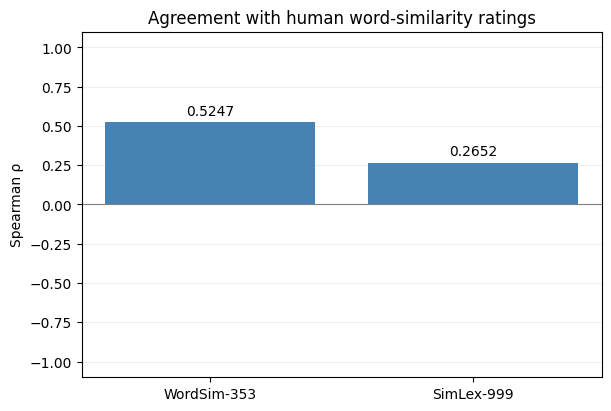

In [60]:
# TODO: Plot the two word-level Spearman correlations.
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
correlations = word_summary_table.set_index("Dataset")["Spearman_rho"]
positions = np.arange(len(correlations))
valid = correlations.notna()
bars = ax.bar(positions[valid], correlations[valid], color="steelblue")
ax.bar_label(bars, fmt="%.4f", padding=3)
for position in positions[~valid]:
    ax.annotate("N/A", (position, 0), xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_xticks(positions, correlations.index)
ax.set(title="Agreement with human word-similarity ratings", ylabel="Spearman ρ", ylim=(-1.1, 1.1))
ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

In [61]:
# Compare ranks rather than subtracting scores on different scales.
def normalized_ranks(values):
    # TODO: Compute normalized ranks using average ranks for ties.
    values = np.asarray(values, dtype=float)
    if values.size < 2:
        return np.full(values.shape, np.nan, dtype=float)
    ranks = pd.Series(values).rank(method="average").to_numpy()
    return (ranks - 1) / (values.size - 1)

In [62]:
# Mine overestimation cases using ranks over the entire valid dataset.
def find_word_error_candidates(scores, k=10):
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("k must be a positive integer")
    ranked = scores.copy()
    ranked["human_rank"] = normalized_ranks(ranked["human_score"])
    ranked["model_rank"] = normalized_ranks(ranked["cosine"])
    ranked["overestimation"] = ranked["model_rank"] - ranked["human_rank"]
    ranked["rank_gap"] = ranked["overestimation"].abs()
    eligible = ranked[(ranked["human_rank"] <= .30) & (ranked["model_rank"] >= .70)]
    status, rule = "strict", "human rank <= 0.30; model rank >= 0.70"
    if eligible.empty:
        eligible = ranked[ranked["overestimation"] > 0]
        status, rule = "fallback_positive", "positive model-minus-human rank"
    if eligible.empty:
        status = "empty"
    top = eligible.sort_values(["overestimation", "word1", "word2", "human_score", "cosine"],
                               ascending=[False, True, True, True, True], kind="mergesort").head(k).copy()
    top["candidate_rank"] = np.arange(1, len(top)+1)
    info = dict(Status=status, Selection=rule, Eligible=len(eligible), Returned=len(top))
    return top.reset_index(drop=True), info


In [63]:
word_candidates, word_selection_records = {}, []
for dataset_name, scores in word_results.items():
    candidates, info = find_word_error_candidates(scores, k=10)
    word_candidates[dataset_name] = candidates
    word_selection_records.append({"Dataset": dataset_name, **info})
word_selection_report = pd.DataFrame(word_selection_records)
print("Candidate pools: largest overestimation within the reported selection rule")
display(word_selection_report)


Candidate pools: largest overestimation within the reported selection rule


,Dataset,Status,Selection,Eligible,Returned
0,WordSim-353,strict,human rank <= 0.30; model rank >= 0.70,14,10
1,SimLex-999,strict,human rank <= 0.30; model rank >= 0.70,70,10


In [64]:
# Select the highest-priority available candidate for each dataset.
selected_words = []
for name, candidates in word_candidates.items():
    if candidates.empty:
        print(f"No analysis candidate available for {name}; skipped.")
        continue
    selected_words.append({**candidates.iloc[0].to_dict(), "Dataset": name})

word_examples = pd.DataFrame(selected_words, columns=[
    "row_id", "word1", "word2", "human_score", "cosine", "human_rank", "model_rank",
    "overestimation", "rank_gap", "candidate_rank", "Dataset",
])


In [65]:
display(word_examples[["Dataset", "word1", "word2", "human_score", "cosine"]].rename(
    columns={"human_score": "Human score", "cosine": "Cosine"}).round(4))
display(word_examples[["Dataset", "candidate_rank", "human_rank", "model_rank", "rank_gap"]].rename(
    columns={"candidate_rank": "Candidate rank", "human_rank": "Human rank",
             "model_rank": "Model rank", "rank_gap": "Rank gap"}).round(4))


,Dataset,word1,word2,Human score,Cosine
0,WordSim-353,Wednesday,news,2.22,0.7454
1,SimLex-999,easy,difficult,0.58,0.8345


,Dataset,Candidate rank,Human rank,Model rank,Rank gap
0,WordSim-353,1,0.0749,0.8818,0.8069
1,SimLex-999,1,0.0573,0.9346,0.8773


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۳.۲</b>

<p><strong>سؤال ۱.</strong> دو نمونه انتخاب‌شده چه اختلافی میان رتبه‌بندی مدل و انسان نشان می‌دهند؟ برای هر نمونه یک توضیح احتمالی ارائه دهید.</p>

<p><strong>سؤال ۲.</strong> تفاوت Semantic Similarity و Semantic Relatedness چیست؟ با توجه به این تفاوت، نتایج دو مجموعه‌داده را مقایسه کنید. آیا واژه‌های متضاد نیز می‌توانند شباهت برداری بالایی داشته باشند؟ چرا؟</p>

{{پاسخ_خود_را_اینجا_بنویسید}}

</div>


<div dir="rtl" align="right">

### ۳.۳ ساخت بردار جمله و ارزیابی Sentence Similarity

**صورت مسئله**

با استفاده از بردارهای GloVe، برای هر جمله یک بردار بسازید و دو روش **Mean Pooling** و **Rank-Weighted Pooling** را روی STS Benchmark مقایسه کنید:

$$s_{\mathrm{mean}}=\frac{1}{n}\sum_{i=1}^{n}e(w_i),\qquad
s_{\mathrm{weighted}}=\frac{\sum_{i=1}^{n}\ln(r(w_i))\,e(w_i)}{\sum_{i=1}^{n}\ln(r(w_i))}.$$

در این روابط، $n$ تعداد توکن‌های دارای بردار معتبر و $r(w_i)$ رتبه واژه در ترتیب اصلی فایل GloVe (از ۱) است.

**آنچه باید انجام دهید**

- توابع `mean_sentence_embedding` و `weighted_sentence_embedding` را تکمیل کنید و نتایج آن‌ها را با مثال‌های عددی موجود بررسی کنید. پیش‌پردازش جملات با تابع `tokenize_sentence` انجام می‌شود.
- تابع `score_sentence_pairs` را تکمیل کنید تا شباهت Cosine دو روش را برای جفت‌جمله‌ها محاسبه کند. خروجی `(common, valid_counts)` باشد؛ `common` شامل `row_id`، دو جمله، `gold_score`، `cosine_mean` و `cosine_weighted` و `valid_counts` شامل تعداد جفت‌های معتبر هر روش با کلیدهای `mean` و `weighted` است.
- تابع `evaluate_sts` را تکمیل کنید تا برای هر روش تعداد جفت‌های معتبر، Coverage و Spearman را گزارش کند. خروجی آن `(summary, common)` است؛ `summary` برای هر روش باید ستون‌های `Method`، `N_total`، `N_valid_own`، `N_valid_common`، `Excluded_common`، `Coverage_common` و `Spearman_rho` را داشته باشد.
- دو نمودار پراکندگی برای مقایسه امتیاز انسانی و Cosine رسم کنید. بازه محورهای دو نمودار یکسان باشد.
- تابع `sentence_weight_details` را تکمیل کنید تا برای هر واژه دارای بردار معتبر، تعداد تکرار، رتبه آن در GloVe، مقدار `ln(rank)` و سهم آن از مجموع وزن‌ها را به درصد محاسبه کند. در محاسبه سهم وزن، تعداد تکرار هر واژه را لحاظ کنید. اگر مجموع وزن‌ها صفر بود، سهم وزن را `NaN` در نظر بگیرید.
- نمونه‌های انتخاب‌شده در نوت‌بوک را بررسی کنید: یک نمونه دارای OOV، یک نمونه با نتیجه بهتر در روش وزن‌دار و یک نمونه با نتیجه ضعیف‌تر. جدول سهم وزن واژه‌ها را نیز تحلیل کنید.

**خروجی مورد انتظار**

- نتایج دو روش Pooling و جدول وزن واژه‌ها.
- جدول Coverage و Spearman، تعداد توکن‌های OOV و دو نمودار پراکندگی.
- مقایسه و تحلیل سه جفت‌جمله انتخاب‌شده براساس امتیازهای انسانی، رتبه‌ها و اثر وزن‌دهی.

**نکات و محدودیت‌ها**

- واژه‌های تکراری را حفظ کنید و توکن‌های OOV را در میانگین‌گیری لحاظ نکنید. بردارهای واژه‌ها را پیش از تجمیع نرمال نکنید.
- در روش وزن‌دار از $\ln(r(w))$ استفاده کنید. در صورت نبود واژه معتبر، صفرشدن مجموع وزن‌ها یا نامعتبر بودن بردار نهایی، `None` برگردانید.
- جفتی معتبر مشترک است که امتیاز انسانی آن متناهی باشد و هر دو روش برای هر دو جمله بردار معتبر (غیر از `None`) تولید کنند. Spearman هر دو روش را فقط روی این جفت‌ها محاسبه کنید؛ برای موارد نامعتبر Cosine صفر در نظر نگیرید.
- در جدول `summary`، مقدار `Method` باید `Mean` یا `Rank-Weighted` باشد. `N_total` تعداد کل جفت‌ها، `N_valid_own` تعداد جفت‌های معتبر هر روش به‌تنهایی و `N_valid_common` تعداد جفت‌های معتبر مشترک است. همچنین `Excluded_common = N_total - N_valid_common` و `Coverage_common = N_valid_common / N_total` (بین صفر و یک) است. `Spearman_rho` نیز با تابع بخش ۲.۲ روی جفت‌های مشترک محاسبه شود.
- در خروجی `common`، شناسه `row_id` شماره سطر اصلی مجموعه‌داده از صفر است؛ ترتیب سطرها حفظ شود.
- خروجی `sentence_weight_details` یک DataFrame با ستون‌های `Token`، `Count`، `GloVe rank`، `ln(rank)` و `Weight share (%)` به همین ترتیب است. واژه‌های OOV یا دارای بردار نامعتبر را لحاظ نکنید و ترتیب سطرها را مطابق اولین وقوع واژه‌ها در جمله حفظ کنید.

</div>


In [66]:
# ==============================================================
# Part 3.3 - Sentence similarity evaluation
# ==============================================================

def tokenize_sentence(sentence):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", sentence.lower())

sentence = "A student reads books."
print("Sentence:", sentence)
display(pd.DataFrame({"Token": tokenize_sentence(sentence),
                      "Has GloVe vector": [word in similarity_embeddings for word in tokenize_sentence(sentence)]}))


Sentence: A student reads books.


,Token,Has GloVe vector
0,a,True
1,student,True
2,reads,True
3,books,True


In [67]:
def mean_sentence_embedding(sentence, embeddings):
    # TODO: Build a sentence vector using mean pooling.
    vectors = [
        embeddings[token] for token in tokenize_sentence(sentence)
        if is_valid_embedding(embeddings.get(token))
    ]
    if not vectors:
        return None
    pooled = np.mean(vectors, axis=0, dtype=np.float64)
    return pooled if is_valid_embedding(pooled) else None

In [68]:
# A repeated token contributes once for each occurrence.
toy_embeddings = {"cat": np.array([2., 0.]), "dog": np.array([0., 2.])}
mean_checks = pd.DataFrame([
    {"Sentence": text, "Mean vector": mean_sentence_embedding(text, toy_embeddings)}
    for text in ("cat dog", "cat cat dog", "cat unknown", "unknown")
])
mean_checks["Mean vector"] = mean_checks["Mean vector"].map(lambda vector: np.round(vector, 4) if vector is not None else None)
display(mean_checks)
assert np.allclose(mean_sentence_embedding("cat cat dog", toy_embeddings), [4/3, 2/3])
assert mean_sentence_embedding("unknown", toy_embeddings) is None


,Sentence,Mean vector
0,cat dog,"[1.0, 1.0]"
1,cat cat dog,"[1.3333, 0.6667]"
2,cat unknown,"[2.0, 0.0]"
3,unknown,None


In [69]:
def weighted_sentence_embedding(sentence, embeddings, rank_map):
    # TODO: Build a sentence vector using ln(original GloVe rank) weights.
    ranked = list(ranked_tokens(sentence, embeddings, rank_map))
    if not ranked:
        return None

    _, vectors, ranks = zip(*ranked)
    weights = np.log(np.asarray(ranks, dtype=np.float64))
    if not weights.any():
        return None
    pooled = np.average(np.asarray(vectors, dtype=np.float64), axis=0, weights=weights)
    return pooled if is_valid_embedding(pooled) else None

def ranked_tokens(sentence, embeddings, rank_map):
    # Keep token repetitions and the original 1-based GloVe file ranks.
    for token in tokenize_sentence(sentence):
        vector = embeddings.get(token)
        rank = rank_map.get(token)
        if rank is not None and np.isfinite(rank) and rank >= 1 and is_valid_embedding(vector):
            yield token, vector, rank

In [70]:
toy_ranks = {"cat": 2, "dog": 8}
weighted_checks = pd.DataFrame([
    {"Sentence": text, "Mean": np.round(mean_sentence_embedding(text, toy_embeddings), 4),
     "Rank-Weighted": np.round(weighted_sentence_embedding(text, toy_embeddings, toy_ranks), 4)}
    for text in ("cat dog", "cat cat dog")
])
display(weighted_checks)
assert np.allclose(weighted_sentence_embedding("cat dog", toy_embeddings, toy_ranks), [.5, 1.5])
assert weighted_sentence_embedding("cat", toy_embeddings, {"cat": 1}) is None


,Sentence,Mean,Rank-Weighted
0,cat dog,"[1.0, 1.0]","[0.5, 1.5]"
1,cat cat dog,"[1.3333, 0.6667]","[0.8, 1.2]"


In [71]:
# Inspect actual GloVe weights in an independent introductory sentence.
weight_sentence = sentence
print("Sentence:", weight_sentence)
example_weight_table = pd.DataFrame([
    {"Word": word, "GloVe rank": glove_ranks[word], "Weight: ln(rank)": np.log(glove_ranks[word])}
    for word in dict.fromkeys(tokenize_sentence(weight_sentence)) if word in glove_ranks
])
display(example_weight_table.round(4))


Sentence: A student reads books.


,Word,GloVe rank,Weight: ln(rank)
0,a,8,2.0794
1,student,1284,7.1577
2,reads,7894,8.9739
3,books,1146,7.0440


In [72]:
def score_sentence_pairs(rows, embeddings, rank_map):
    # TODO: Score the common valid sentence pairs for both pooling methods.
    scored = []
    valid_counts = {"mean": 0, "weighted": 0}
    poolers = {
        "mean": lambda sentence: mean_sentence_embedding(sentence, embeddings),
        "weighted": lambda sentence: weighted_sentence_embedding(sentence, embeddings, rank_map),
    }
    columns = ["row_id", "sentence1", "sentence2", "gold_score", "cosine_mean", "cosine_weighted"]

    for row_id, (first, second, score) in enumerate(
        rows[["sentence1", "sentence2", "score"]].itertuples(index=False, name=None)
    ):
        gold_score = pd.to_numeric(score, errors="coerce")
        if not np.isfinite(gold_score) or not isinstance(first, str) or not isinstance(second, str):
            continue

        cosines = {}
        for method, pool in poolers.items():
            first_vector, second_vector = pool(first), pool(second)
            if first_vector is None or second_vector is None:
                continue
            cosine = manual_cosine_similarity(first_vector, second_vector)
            if np.isfinite(cosine):
                valid_counts[method] += 1
                cosines[method] = cosine

        if len(cosines) == len(poolers):
            scored.append((row_id, first, second, gold_score, cosines["mean"], cosines["weighted"]))

    return pd.DataFrame(scored, columns=columns), valid_counts

In [73]:
# Compute the two correlations on exactly the same scored pairs.
def evaluate_sts(rows, embeddings, rank_map):
    # TODO: Compare coverage and Spearman on the common evaluation set.
    common, valid_counts = score_sentence_pairs(rows, embeddings, rank_map)
    n_total, n_common = len(rows), len(common)
    summary = []
    for key, name in (("mean", "Mean"), ("weighted", "Rank-Weighted")):
        rho, _ = safe_spearman(common["gold_score"], common[f"cosine_{key}"])
        summary.append({
            "Method": name,
            "N_total": n_total,
            "N_valid_own": valid_counts[key],
            "N_valid_common": n_common,
            "Excluded_common": n_total - n_common,
            "Coverage_common": n_common / n_total if n_total else 0.0,
            "Spearman_rho": rho,
        })
    return pd.DataFrame(summary), common

sts_summary_table, sts_pair_scores = evaluate_sts(sts_test_pairs, similarity_embeddings, glove_ranks)
sts_report = sts_summary_table[["Method", "N_valid_own", "N_valid_common", "Spearman_rho"]].copy()
sts_report.columns = ["Method", "Valid pairs", "Common pairs", "Spearman (rho)"]
sts_report["Common coverage (%)"] = (100*sts_summary_table["Coverage_common"]).round(2)
display(sts_report.round(4))

,Method,Valid pairs,Common pairs,Spearman (rho),Common coverage (%)
0,Mean,1379,1379,0.4276,100.0
1,Rank-Weighted,1379,1379,0.5310,100.0


In [74]:
# Count token occurrences over the entire test split, including repeated sentences.
all_test_tokens = [word for row in sts_test_pairs.itertuples(index=False)
                   for text in (row.sentence1, row.sentence2) for word in tokenize_sentence(text)]
oov_count = sum(word not in similarity_embeddings for word in all_test_tokens)
display(pd.DataFrame([{"Total tokens": len(all_test_tokens), "OOV tokens": oov_count,
                       "OOV (%)": round(100*oov_count/len(all_test_tokens), 2)}]))


,Total tokens,OOV tokens,OOV (%)
0,26731,654,2.45


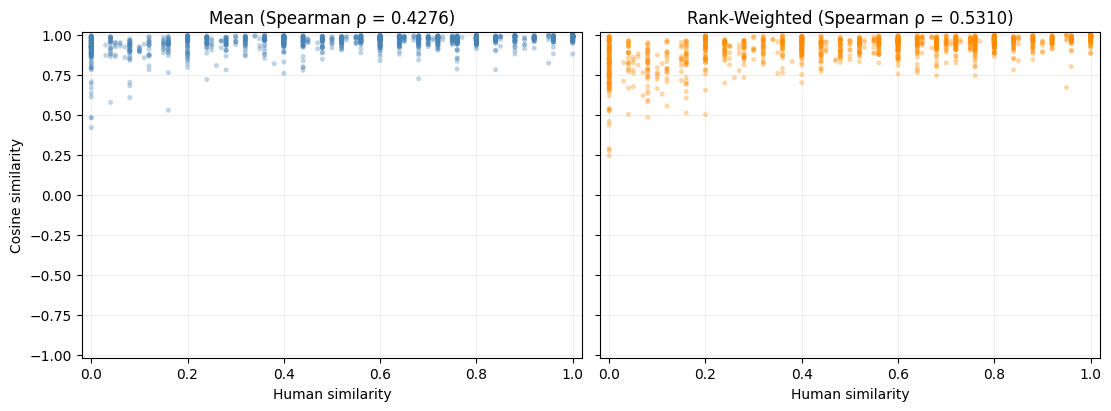

In [75]:
# TODO: Plot the two STS scatter plots on matching axes.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True, layout="constrained")
for ax, (method, name, color) in zip(axes, (
    ("mean", "Mean", "steelblue"),
    ("weighted", "Rank-Weighted", "darkorange"),
)):
    ax.scatter(
        sts_pair_scores["gold_score"], sts_pair_scores[f"cosine_{method}"],
        s=13, alpha=0.35, color=color, edgecolors="none",
    )
    rho = sts_summary_table.loc[sts_summary_table["Method"] == name, "Spearman_rho"].iloc[0]
    label = f"{rho:.4f}" if np.isfinite(rho) else "N/A"
    ax.set(title=f"{name} (Spearman ρ = {label})", xlabel="Human similarity", xlim=(-0.02, 1.02))
    ax.set_ylim(-1.02, 1.02)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Cosine similarity")
plt.show()

In [76]:
# Preserve every evaluated record when computing ranks and token counts.
def rank_sts_pairs(scores, embeddings):
    if not scores["gold_score"].between(0, 1).all():
        raise ValueError("Expected STS gold scores on a 0..1 scale")
    ranked = scores.copy()
    ranked["gold_rank"] = normalized_ranks(ranked["gold_score"])
    for method in ("mean", "weighted"):
        ranked[f"{method}_rank"] = normalized_ranks(ranked[f"cosine_{method}"])
        ranked[f"gap_{method}"] = abs(ranked["gold_rank"]-ranked[f"{method}_rank"])
    ranked["weighted_gain"] = ranked["gap_mean"]-ranked["gap_weighted"]
    ranked["oov_count"] = [sum(word not in embeddings for text in (row.sentence1, row.sentence2)
                              for word in tokenize_sentence(text)) for row in ranked.itertuples(index=False)]
    return ranked


In [77]:
def select_sts_candidates(ranked, mode, k=10):
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("k must be a positive integer")
    rules = {
        "oov": ((ranked["gold_score"] >= .75) & (ranked["oov_count"] > 0),
                "gap_mean", False, "gold >= 0.75; OOV > 0; largest Mean rank gap"),
        "improved": (ranked["weighted_gain"] > 0, "weighted_gain", False, "positive weighted gain; largest first"),
        "worsened": (ranked["weighted_gain"] < 0, "weighted_gain", True, "negative weighted gain; smallest first"),
    }
    if mode not in rules:
        raise ValueError("Unknown candidate group")
    mask, metric, ascending, rule = rules[mode]
    eligible = ranked.loc[mask]
    top = eligible.sort_values([metric, "sentence1", "sentence2", "gold_score", "cosine_mean", "cosine_weighted"],
                               ascending=[ascending, True, True, True, True, True], kind="mergesort").head(k).copy()
    top["candidate_rank"] = np.arange(1, len(top)+1)
    info = dict(Status="empty" if top.empty else "available", Selection=rule,
                Eligible=len(eligible), Returned=len(top))
    return top.reset_index(drop=True), info


In [78]:
sts_ranked_pairs = rank_sts_pairs(sts_pair_scores, similarity_embeddings)
sts_candidates, sts_selection_records = {}, []
for mode in ("oov", "improved", "worsened"):
    candidates, info = select_sts_candidates(sts_ranked_pairs, mode, k=10)
    sts_candidates[mode] = candidates
    sts_selection_records.append({"Group": mode, **info})
sts_selection_report = pd.DataFrame(sts_selection_records)
print("Candidate pools: rankings are within each reported group")
display(sts_selection_report)


Candidate pools: rankings are within each reported group


,Group,Status,Selection,Eligible,Returned
0,oov,available,gold >= 0.75; OOV > 0; largest Mean rank gap,120,10
1,improved,available,positive weighted gain; largest first,839,10
2,worsened,available,negative weighted gain; smallest first,531,10


In [79]:
# Select one available candidate from each analysis group.
selected_sentences = []
for category in ("oov", "improved", "worsened"):
    candidates = sts_candidates[category]
    if candidates.empty:
        print(f"No analysis candidate available for STS group '{category}'; skipped.")
        continue
    selected_sentences.append({**candidates.iloc[0].to_dict(), "category": category})

sts_examples = pd.DataFrame(selected_sentences, columns=[
    "row_id", "sentence1", "sentence2", "gold_score", "cosine_mean", "cosine_weighted",
    "gold_rank", "mean_rank", "gap_mean", "weighted_rank", "gap_weighted",
    "weighted_gain", "oov_count", "candidate_rank", "category",
])


In [80]:
for example in sts_examples.itertuples(index=False):
    print("Case:", example.category, "| Candidate rank:", example.candidate_rank)
    print("Sentence 1:", example.sentence1)
    print("Sentence 2:", example.sentence2)
    print(f"Human score: {example.gold_score:.2f} | Human rank: {example.gold_rank:.4f}")
    for number, text in enumerate((example.sentence1, example.sentence2), start=1):
        print(f"OOV in sentence {number}:", [word for word in tokenize_sentence(text) if word not in similarity_embeddings])
    print(f"Weighted gain: {example.weighted_gain:+.4f}")
    display(pd.DataFrame([
        {"Method": "Mean", "Cosine": example.cosine_mean, "Model rank": example.mean_rank, "Rank gap": example.gap_mean},
        {"Method": "Rank-Weighted", "Cosine": example.cosine_weighted, "Model rank": example.weighted_rank, "Rank gap": example.gap_weighted},
    ]).round(4))


Case: oov | Candidate rank: 1
Sentence 1: Mt Gox reveals 200,000 'forgotten' bitcoin haul
Sentence 2: Mt Gox finds 200,000 'forgotten' bitcoins
Human score: 1.00 | Human rank: 0.9652
OOV in sentence 1: ['gox', 'bitcoin']
OOV in sentence 2: ['gox', 'bitcoins']
Weighted gain: +0.1676
Case: improved | Candidate rank: 1
Sentence 1: Two boys playing a game of flag football.
Sentence 2: Two boys are playing flag football.
Human score: 1.00 | Human rank: 0.9652
OOV in sentence 1: []
OOV in sentence 2: []
Weighted gain: +0.4144
Case: worsened | Candidate rank: 1
Sentence 1: This doesn't answer your question, but:
Sentence 2: This is a part answer to your question
Human score: 0.20 | Human rank: 0.1996
OOV in sentence 1: ["doesn't"]
OOV in sentence 2: []
Weighted gain: -0.3694


,Method,Cosine,Model rank,Rank gap
0,Mean,0.8797,0.0631,0.9020
1,Rank-Weighted,0.8850,0.2308,0.7344


,Method,Cosine,Model rank,Rank gap
0,Mean,0.9699,0.4956,0.4695
1,Rank-Weighted,0.9867,0.9100,0.0552


,Method,Cosine,Model rank,Rank gap
0,Mean,0.9699,0.4985,0.2990
1,Rank-Weighted,0.9835,0.8679,0.6684


In [81]:
# Include repetitions when measuring each word's share of the pooling weights.
def sentence_weight_details(text, embeddings, rank_map):
    # TODO: Compute each valid word's contribution to the pooling weights.
    columns = ["Token", "Count", "GloVe rank", "ln(rank)", "Weight share (%)"]
    counts, ranks = Counter(), {}
    for token, _, rank in ranked_tokens(text, embeddings, rank_map):
        counts[token] += 1
        ranks[token] = rank

    details = pd.DataFrame(
        [(token, count, ranks[token], np.log(ranks[token])) for token, count in counts.items()],
        columns=columns[:-1],
    )
    contributions = details["Count"] * details["ln(rank)"]
    total = contributions.sum()
    details["Weight share (%)"] = 100 * contributions / total if total > 0 else np.nan
    return details

# Prefer a worsened example; otherwise inspect an available selected group.
weighting_examples = sts_examples[sts_examples["category"] == "worsened"]
if weighting_examples.empty and not sts_examples.empty:
    print("No worsened example available; showing weights for another selected group.")
    weighting_examples = sts_examples
if weighting_examples.empty:
    print("No STS analysis example available; weight details skipped.")
else:
    weighting_case = weighting_examples.iloc[0]
    print("Weight details for group:", weighting_case.category)
    for text in (weighting_case.sentence1, weighting_case.sentence2):
        print("Sentence:", text)
        display(sentence_weight_details(text, similarity_embeddings, glove_ranks).round(4))

Weight details for group: worsened
Sentence: This doesn't answer your question, but:
Sentence: This is a part answer to your question


,Token,Count,GloVe rank,ln(rank),Weight share (%)
0,this,1,38,3.6376,13.1072
1,answer,1,2169,7.6820,27.6805
2,your,1,393,5.9738,21.5253
3,question,1,996,6.9037,24.8761
4,but,1,35,3.5553,12.8109


,Token,Count,GloVe rank,ln(rank),Weight share (%)
0,this,1,38,3.6376,10.2090
1,is,1,15,2.7081,7.6003
2,a,1,8,2.0794,5.8360
3,part,1,154,5.0370,14.1364
4,answer,1,2169,7.6820,21.5599
5,to,1,5,1.6094,4.5170
6,your,1,393,5.9738,16.7657
7,question,1,996,6.9037,19.3757


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۳.۳ — تحلیل STS</b>

<p><strong>سؤال ۱.</strong> سه نمونه انتخاب‌شده چه تفاوتی در شباهت انسانی و پیش‌بینی دو روش دارند؟ تغییر اختلاف رتبه پس از وزن‌دهی را برای هر نمونه توضیح دهید.</p>

<p><strong>سؤال ۲.</strong> با توجه به واژه‌های OOV و جدول وزن‌ها، علت‌های احتمالی بهبود یا افت روش Rank-Weighted را بررسی کنید. آیا نتیجه بهتر در Spearman به معنای بهبود همه جفت‌جمله‌هاست؟</p>

{{پاسخ_خود_را_اینجا_بنویسید}}

</div>


<div dir="rtl" align="right">

### ۳.۴ بررسی اثر ترتیب واژه‌ها

**صورت مسئله**

دو جمله زیر از واژه‌های یکسانی تشکیل شده‌اند، اما ترتیب آن‌ها متفاوت است:

1. `The dog chased the man.`
2. `The man chased the dog.`

**آنچه باید انجام دهید**

- با استفاده از دو روش بخش قبل، بردار هر جمله را محاسبه کنید.
- در هر روش، بردار دو جمله را با `np.allclose` مقایسه کنید و مقدار Cosine و بیشترین اختلاف مطلق مؤلفه‌ها را گزارش دهید.

**خروجی مورد انتظار**

- جدول تعداد تکرار واژه‌ها و جدول مقایسه نتایج دو روش با ستون‌های `Method`، `Same vector (allclose)`، `Max absolute difference` و `Cosine`.

**نکات و محدودیت‌ها**

- برای `np.allclose` از `rtol=1e-10` و `atol=1e-12` استفاده کنید. این آزمایش مستقل از ارزیابی STS است و نباید به داده‌های Test اضافه شود.

</div>


In [82]:
# ==============================================================
# Part 3.4 - Controlled word-order experiment
# ==============================================================

# Provided inputs: change word order while preserving token multiplicities.
order_sentences = ("The dog chased the man.", "The man chased the dog.")
order_tokens = [tokenize_sentence(text) for text in order_sentences]
assert order_tokens[0] != order_tokens[1]
assert sorted(order_tokens[0]) == sorted(order_tokens[1])
assert all(word in similarity_embeddings and is_valid_embedding(similarity_embeddings[word])
           for tokens in order_tokens for word in tokens)
for number, text in enumerate(order_sentences, start=1):
    print(f"Sentence {number}:", text)
order_token_counts = pd.DataFrame([
    {"Token": word, "Sentence 1 count": order_tokens[0].count(word),
     "Sentence 2 count": order_tokens[1].count(word)}
    for word in sorted(set(order_tokens[0]))
])
display(order_token_counts)


Sentence 1: The dog chased the man.
Sentence 2: The man chased the dog.


,Token,Sentence 1 count,Sentence 2 count
0,chased,1,1
1,dog,1,1
2,man,1,1
3,the,2,2


In [83]:
# TODO: Compare the two controlled sentences within each pooling method.
order_results = []
for method, pool in (
    ("Mean", lambda text: mean_sentence_embedding(text, similarity_embeddings)),
    ("Rank-Weighted", lambda text: weighted_sentence_embedding(text, similarity_embeddings, glove_ranks)),
):
    first, second = (pool(text) for text in order_sentences)
    if first is None or second is None:
        raise ValueError(f"{method} did not produce both controlled sentence vectors.")
    order_results.append({
        "Method": method,
        "Same vector (allclose)": bool(np.allclose(first, second, rtol=1e-10, atol=1e-12)),
        "Max absolute difference": float(np.max(np.abs(first - second))),
        "Cosine": manual_cosine_similarity(first, second),
    })
order_comparison = pd.DataFrame(order_results)
display(order_comparison.style.format({
    "Max absolute difference": "{:.2e}",
    "Cosine": "{:.12f}",
}))

,Method,Same vector (allclose),Max absolute difference,Cosine
0,Mean,True,0.00e+00,1.000000000000
1,Rank-Weighted,True,4.44e-16,1.000000000000


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۳.۴ — ترتیب واژه‌ها</b>

<p><strong>سؤال ۱.</strong> نتیجه مقایسه بردار دو جمله در هر روش چیست؟ آیا روش Rank-Weighted می‌تواند تفاوت ترتیب واژه‌ها را نشان دهد؟</p>

<p><strong>سؤال ۲.</strong> این آزمایش چه محدودیتی از روش‌های تجمیع به‌کاررفته در این سؤال را نشان می‌دهد؟</p>

{{پاسخ_خود_را_اینجا_بنویسید}}

</div>


---

<div dir="rtl" align="right">

## جمع‌بندی

در چند بند، یافته‌های خود را از کل تکلیف جمع‌بندی کنید.

- **مهم‌ترین نتایج به‌دست‌آمده:** {{پاسخ_خود_را_اینجا_بنویسید}}
- **چالش‌ها و محدودیت‌های روش‌های به‌کاررفته:** {{پاسخ_خود_را_اینجا_بنویسید}}
- **پیشنهاد برای بهبود یا ادامه‌ی کار:** {{پاسخ_خود_را_اینجا_بنویسید}}

</div>

<div dir="rtl" align="right">

## منابع و ابزارهای کمکی

هر منبعی که در انجام این تکلیف از آن استفاده کرده‌اید (مقاله، مستندات کتابخانه، مخزن کد، پست وبلاگ) و نیز — مطابق سیاست درس — هرگونه استفاده از ابزارهای هوش مصنوعی مولد را در جدول زیر ذکر کنید. اعلام نکردن منابع و ابزارهای استفاده‌شده، مصداق نقض صداقت علمی است.

| ردیف | منبع یا ابزار | محل استفاده (شماره‌ی بخش) | نحوه‌ی استفاده |
|---|---|---|---|
| ۱ | [Skip-gram Word2Vec Algorithm Explained](https://leshem-ido.medium.com/skip-gram-word2vec-algorithm-explained-85cd67a45ffa) | ۱.۱ | از این لینک برای پیاده‌سازی الگوریتم Skip-gram استفاده شد. |
| ۲ | [Gradient Checking](https://wiki.shav.dev/artificial-intelligence/practical-aspects-of-deep-learning/gradient-checking) | بخش ۱.۱ برای پیاده‌سازی gradient checking | برای بررسی روش gradient checking و مقایسه‌ی گرادیان تحلیلی با گرادیان عددی استفاده شد. |
| ۳ | [What exactly is gradient checking?](https://stackoverflow.com/questions/47506521/what-exactly-is-gradient-checking) | بخش ۱.۱ برای پیاده‌سازی gradient checking | برای درک مفهوم gradient checking و نحوه‌ی اعتبارسنجی گرادیان‌ها استفاده شد. |
| ۴ | [Debugging: Gradient Checking](https://ufldl.stanford.edu/tutorial/supervised/DebuggingGradientChecking/) | بخش ۱.۱ برای پیاده‌سازی gradient checking | برای پیاده‌سازی gradient checking و تشخیص اشتباهات محاسبه‌ی گرادیان‌ها به کار رفت. |
| ۵ | [PCA and proportion of variance explained](https://stats.stackexchange.com/questions/22569/pca-and-proportion-of-variance-explained?newreg=4d4f34921d6d4e8294252f33a6123006) | بخش ۱.۳ برای تفسیر Explained Variance Ratio | برای توضیح اینکه مجموع Explained Variance Ratio دو مؤلفه‌ی نخست، چه درصدی از واریانس کل داده‌ها را توسط PCA حفظ می‌کند استفاده شد. |
| ۶ | [گفت‌وگوی اول با ChatGPT](https://chatgpt.com/share/6b0996bd-8df0-83ed-8dcb-0e39c32f573f) | تمام بخش‌های نوت‌بوک | کمک در انجام تمرین |
| ۷ | [گفت‌وگوی دوم با ChatGPT](https://chatgpt.com/share/6b0996db-c1a0-83eb-a4c7-0ecc8be74e6b) | تمام بخش‌های نوت‌بوک | کمک در انجام تمرین |

</div>

<div dir="rtl" align="right">

## چک‌لیست پیش از ارسال

- [ ] جدول مشخصات دانشجو تکمیل شده است.
- [x] همه‌ی سلول‌های دارای نشانه‌ی `WRITE YOUR CODE HERE` تکمیل شده‌اند.
- [ ] همه‌ی سلول‌های پاسخ تشریحی تکمیل شده و هیچ `{{پاسخ_خود_را_اینجا_بنویسید}}` باقی نمانده است.
- [ ] بخش جمع‌بندی و جدول منابع و ابزارهای کمکی تکمیل شده است.
- [x] نوت‌بوک با `Restart & Run All` بدون خطا اجرا شده و خروجی همه‌ی سلول‌ها در فایل ذخیره شده است.
- [ ] نام فایل مطابق الگوی `NLP_CA{n}_{LASTNAME}_{STUDENTID}.ipynb` است.

</div>

---

<div dir="rtl" align="right">

## قوانین تحویل و صداقت علمی

### ۱. مهلت و نحوه‌ی ارسال

- مهلت تحویل: {{تاریخ_تحویل}}
- مهلت تحویل با تأخیر: {{تاریخ_تحویل_با_تأخیر}} — با اعمال {{جریمه_تأخیر}}
- فایل ارسالی باید با این قالب نام‌گذاری شود: `NLP_CA{n}_{LASTNAME}_{STUDENTID}.ipynb`
- تنها فایل نوت‌بوک اجراشده پذیرفته می‌شود. به تکالیفی که به‌صورت کاغذی تحویل داده شوند یا به‌صورت تصویر در سامانه بارگذاری شوند، ترتیب اثری داده نخواهد شد.

### ۲. صداقت علمی

- نوت‌بوک تعداد مشخصی از دانشجویان که به‌صورت تصادفی انتخاب می‌شوند بررسی خواهد شد. این بررسی‌ها اطمینان حاصل می‌کنند که کدی که نوشته‌اید واقعاً پاسخ‌های موجود در نوت‌بوک شما را تولید می‌کند. ارائه‌ی پاسخ‌های درست بدون کدی که آن پاسخ‌ها را تولید کرده باشد، موردی جدی از عدم صداقت علمی محسوب می‌شود.
- بررسی‌های خودکار برای تشخیص سرقت علمی روی نوت‌بوک‌ها انجام می‌شود. کپی کردن کد از دیگران نیز موردی جدی از عدم صداقت علمی است.
- این تکلیف باید به‌صورت تک‌نفره انجام شود و پاسخ‌ها باید نتیجه‌ی فعالیت شخص نویسنده باشد؛ هم‌فکری و نوشتن مشترک تمرین نیز مجاز نیست. در صورت مشاهده‌ی تشابه، نمره‌ی تمرین برای همه‌ی افراد مشارکت‌کننده صفر و موضوع به استاد گزارش می‌شود.

### ۳. کد و گزارش

- همه‌ی کدهای پیوست گزارش باید قابلیت اجرای مجدد داشته باشند. اگر اجرای دوباره به تنظیمات خاصی نیاز دارد، آن تنظیمات را در گزارش ذکر کنید.
- همه‌ی کدها باید توسط خودتان اجرا شده و نتایج اجرا در فایل ارسالی قابل مشاهده باشد. به کدهایی که نتیجه‌ی اجرای آن‌ها در فایل ارسالی مشخص نباشد نمره‌ای تعلق نمی‌گیرد.
- خوانایی گزارش و دقت تحلیل‌ها در نمره‌دهی اهمیت ویژه دارد.

### ۴. پرسش و پاسخ

- پرسش‌های خود درباره‌ی این تکلیف را در {{کانال_پرسش_و_پاسخ}} یا از طریق ایمیل {{ایمیل_دستیار}} مطرح کنید و در ایمیل‌ها حتماً چیف تی‌ای درس (msabour.official@gmail.com) را cc کنید.
